In [4]:
# %% [1] SETUP: paket, konfigurasi, versi, folder output
import os, sys, platform, time, json, math, warnings, hashlib, zipfile, subprocess, importlib, pickle, datetime, gc
from importlib import metadata
import numpy as np
import pandas as pd

def _ensure(import_name, pip_name):
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f'Memasang {pip_name} ...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])
_ensure('imblearn', 'imbalanced-learn')
_ensure('openpyxl', 'openpyxl')

import matplotlib
if 'google.colab' not in sys.modules and not os.environ.get('DISPLAY') and os.environ.get('MPLBACKEND') is None:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler, NearMiss, TomekLinks, EditedNearestNeighbours

IN_COLAB = 'google.colab' in sys.modules

# ---------------- KONFIGURASI (tidak perlu diubah) ----------------
INPUT_FILENAME   = 'Dataset_Final_.csv'      # file input dipilih eksplisit (bukan "first CSV found")
RANDOM_STATE     = 42
N_SPLITS         = 5                         # outer collision-grouped CV
INNER_SPLITS     = 4                         # inner split (grouped) untuk memilih threshold -> 25% val
N_BOOT           = 1000                      # bootstrap tingkat collision
EQUIV_MARGIN     = 0.01                      # margin kesetaraan praktis ROC-AUC/PR-AUC (keputusan peneliti)
RECALL_TARGETS   = [0.50, 0.80]
FPR_CAPS         = [0.05, 0.10]
CAPACITIES       = [0.05, 0.10]              # kapasitas peninjauan: top-k% skor tertinggi
OHE_MIN_FREQ     = 0.005                     # kategori < 0,5% digabung (infrequent) saat one-hot
NATIONAL_REF     = {'casualty': 132977, 'fatal': 1624}   # angka rujukan yang dikutip manuskrip (Great Britain)
CLAIM_LINEAR_RANGE = (0.90, 0.91)            # klaim manuskrip "model linear selalu 0,90–0,91" (audit §6)
RUN_SENSITIVITY  = True
RUN_CLASS_WEIGHT = True                      # baseline class weighting (suplemen, P2)
RESUME           = True
QUICK_TEST       = os.environ.get('STATS19_QUICK', '0') == '1'
QUICK_FRAC       = float(os.environ.get('STATS19_QUICK_FRAC', '0.2'))
if QUICK_TEST:
    N_BOOT = 200

OUT_DIR  = '/content/hasil_stats19' if IN_COLAB else os.path.abspath('hasil_stats19')
TAB_DIR  = os.path.join(OUT_DIR, 'tables');  FIG_DIR = os.path.join(OUT_DIR, 'figures')
CKPT_DIR = os.path.join(OUT_DIR, 'checkpoints'); PRED_DIR = os.path.join(OUT_DIR, 'predictions')
for d in (OUT_DIR, TAB_DIR, FIG_DIR, CKPT_DIR, PRED_DIR):
    os.makedirs(d, exist_ok=True)

# ---------------- Reproducibility (§8): versi & lingkungan ----------------
def _ver(p):
    try: return metadata.version(p)
    except Exception: return 'n/a'
ENV = {
    'timestamp': datetime.datetime.now().isoformat(timespec='seconds'),
    'python': sys.version.split()[0], 'platform': platform.platform(),
    'cpu_count': os.cpu_count(),
    'libraries': {p: _ver(p) for p in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'imbalanced-learn',
                                       'matplotlib', 'openpyxl']},
    'random_state': RANDOM_STATE, 'quick_test': QUICK_TEST,
}
try:
    import psutil
    ENV['ram_gb'] = round(psutil.virtual_memory().total / 1e9, 1)
except Exception:
    ENV['ram_gb'] = 'n/a'
with open(os.path.join(OUT_DIR, 'environment.json'), 'w') as f:
    json.dump(ENV, f, indent=2)
with open(os.path.join(OUT_DIR, 'requirements_used.txt'), 'w') as f:
    for p, v in ENV['libraries'].items(): f.write(f'{p}=={v}\n')
print(json.dumps(ENV, indent=2))
if QUICK_TEST: print('\n*** MODE QUICK_TEST AKTIF: data disubsampel, hasil hanya untuk uji alur ***')

{
  "timestamp": "2026-11-17T02:32:43",
  "python": "3.13.18",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "cpu_count": 2,
  "libraries": {
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "imbalanced-learn": "0.14.2",
    "matplotlib": "3.10.0",
    "openpyxl": "3.1.5"
  },
  "random_state": 42,
  "quick_test": false,
  "ram_gb": 13.6
}


In [6]:
# %% [2] HELPER: tabel, gambar, metrik, threshold, bootstrap
TABLES = {}
def show(df, title=None, max_rows=60):
    if title: print('\n' + '=' * 100 + f'\n{title}\n' + '=' * 100)
    try:
        from IPython.display import display
        display(df.head(max_rows))
    except Exception:
        print(df.head(max_rows).to_string())

def save_table(df, name, title=None, display_it=True):
    df = df.copy(); TABLES[name] = df
    df.to_csv(os.path.join(TAB_DIR, f'{name}.csv'), index=False)
    if display_it: show(df, title or name)
    return df

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=150, bbox_inches='tight'); plt.show(); plt.close('all')

def safe_div(a, b): return a / b if b else 0.0

def confusion(y, pred):
    y = np.asarray(y).astype(int); pred = np.asarray(pred).astype(int)
    return (int(((y == 1) & (pred == 1)).sum()), int(((y == 0) & (pred == 1)).sum()),
            int(((y == 1) & (pred == 0)).sum()), int(((y == 0) & (pred == 0)).sum()))

def conf_metrics(tp, fp, fn, tn):
    rec = safe_div(tp, tp + fn); prec = safe_div(tp, tp + fp); spec = safe_div(tn, tn + fp)
    den = math.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return dict(recall=rec, precision=prec, specificity=spec, FPR=1 - spec,
                F1=safe_div(2 * prec * rec, prec + rec), F2=safe_div(5 * prec * rec, 4 * prec + rec),
                MCC=((tp * tn - fp * fn) / den) if den > 0 else 0.0, balanced_accuracy=(rec + spec) / 2,
                flagged_fraction=safe_div(tp + fp, tp + fp + fn + tn))

# --- definisi metrik (eksplisit, §3.5): ROC-AUC = area under ROC (sklearn roc_auc_score);
#     PR-AUC = average precision (sklearn average_precision_score; jumlah bertahap, tanpa interpolasi linear).
def thr_f2(y, s):
    p, r, t = precision_recall_curve(y, s); p, r = p[:-1], r[:-1]
    f2 = np.where(4 * p + r > 0, 5 * p * r / np.maximum(4 * p + r, 1e-12), 0.0)
    return t[int(np.argmax(f2))]

def thr_recall(y, s, target):
    fpr, tpr, t = roc_curve(y, s, drop_intermediate=False)
    ok = np.where(tpr >= target)[0]
    return t[ok[0]] if len(ok) else t[-1]

def thr_fpr(y, s, cap):
    fpr, tpr, t = roc_curve(y, s, drop_intermediate=False)
    return t[np.where(fpr <= cap)[0][-1]]

def thr_capacity(s, frac):
    n = len(s); m = max(1, int(math.ceil(frac * n)))
    return np.partition(s, n - m)[n - m]

def op_thresholds(clf_name, yv, sv, st):
    """Threshold: default; dari inner-validation (F2, recall target, FPR cap); kapasitas = top-k% (tanpa label)."""
    ops = {'default': 0.0 if clf_name == 'LinearSVC' else 0.5}
    if yv is not None and sv is not None and yv.sum() > 0 and (yv == 0).sum() > 0:
        ops['F2-optimal (inner-val)'] = thr_f2(yv, sv)
        for t in RECALL_TARGETS: ops[f'recall>={t:.2f} (inner-val)'] = thr_recall(yv, sv, t)
        for c in FPR_CAPS: ops[f'FPR<={c:.2f} (inner-val)'] = thr_fpr(yv, sv, c)
    for k in CAPACITIES: ops[f'top{int(k * 100)}pct (capacity)'] = thr_capacity(st, k)
    return ops

class BootMetric:
    """ROC-AUC & AP berbobot (bobot = multiplisitas collision pada bootstrap tingkat collision); tie ditangani."""
    def __init__(self, y, s):
        order = np.argsort(-s, kind='mergesort'); ss = s[order]
        self.order = order; self.y = y[order].astype(float)
        newg = np.r_[True, ss[1:] != ss[:-1]]; self.gid = np.cumsum(newg) - 1; self.ng = int(self.gid[-1]) + 1
    def metrics(self, w):
        ws = w[self.order]
        pos = np.bincount(self.gid, weights=ws * self.y, minlength=self.ng)
        neg = np.bincount(self.gid, weights=ws * (1 - self.y), minlength=self.ng)
        P, N = pos.sum(), neg.sum()
        if P == 0 or N == 0: return np.nan, np.nan
        cp, cn = np.cumsum(pos), np.cumsum(neg)
        auc = np.sum(pos * (N - cn + 0.5 * neg)) / (P * N)
        ap = np.sum((pos / P) * (cp / np.maximum(cp + cn, 1e-12)))
        return auc, ap

In [7]:
# %% [3] MUAT DATA (file eksplisit) + provenance file
def locate_input():
    # Tambahkan nama-nama alternatif yang kemungkinan diunggah (dengan spasi)
    cands = [
        INPUT_FILENAME,
        os.path.join('/content', INPUT_FILENAME),
        os.path.join('/mnt/user-data/uploads', INPUT_FILENAME),
        '/content/Dataset_Final .csv',
        '/content/Dataset_Final  (1).csv',
        'Dataset_Final .csv'
    ]
    for p in cands:
        if os.path.exists(p): return os.path.abspath(p)
    if IN_COLAB:
        from google.colab import files
        print(f'{INPUT_FILENAME} tidak ditemukan. Silakan upload file tersebut.')
        up = files.upload()
        for name in up:
            if name.startswith(os.path.splitext(INPUT_FILENAME)[0]) or 'Dataset_Final' in name: return os.path.abspath(name)
    raise FileNotFoundError(f'File input {INPUT_FILENAME} tidak ditemukan / tidak diupload.')

INPUT_PATH = locate_input()
sha = hashlib.sha256(open(INPUT_PATH, 'rb').read()).hexdigest()
PROV = {'input_file': os.path.basename(INPUT_PATH), 'path': INPUT_PATH, 'size_bytes': os.path.getsize(INPUT_PATH),
        'modified': datetime.datetime.fromtimestamp(os.path.getmtime(INPUT_PATH)).isoformat(timespec='seconds'),
        'sha256': sha}
print(json.dumps(PROV, indent=2))
STR_COLS = ['accident_index', 'accident_reference', 'accident_reference_veh', 'accident_reference_cas',
            'lsoa_of_accident_location', 'lsoa_of_driver', 'lsoa_of_casualty', 'generic_make_model']
df = pd.read_csv(INPUT_PATH, low_memory=False, dtype={c: str for c in STR_COLS})
N_FILE_ROWS, N_FILE_COLL = len(df), df['accident_index'].nunique()
print('Dimensi file:', df.shape)
if QUICK_TEST:
    rng = np.random.RandomState(RANDOM_STATE)
    coll = df['accident_index'].unique(); keep = set(rng.choice(coll, int(len(coll) * QUICK_FRAC), replace=False))
    df = df[df['accident_index'].isin(keep)].reset_index(drop=True)
    print('QUICK_TEST: baris dipakai =', len(df))
df['row_id'] = np.arange(len(df))

{
  "input_file": "Dataset_Final_.csv",
  "path": "/content/Dataset_Final_.csv",
  "size_bytes": 27650611,
  "modified": "2026-11-17T02:32:22",
  "sha256": "d5ef05fcbb5cab10a8a9a0641c4f962b9f2eaec2946fb9506a8a7c3b6f3aedbd"
}
Dimensi file: (85569, 89)


In [8]:
# %% [3b] REKONSTRUKSI COHORT DARI 3 CSV MENTAH DfT + PERBANDINGAN DENGAN Dataset_Final_
RAW_DIR = '/content'
RAW_FILES = {'collision': 'dft-road-casualty-statistics-collision-2023.csv',
             'vehicle':   'dft-road-casualty-statistics-vehicle-2023.csv',
             'casualty':  'dft-road-casualty-statistics-casualty-2023.csv'}
def _find_raw(fn):
    for base in (RAW_DIR, '.', '/mnt/user-data/uploads'):
        p = os.path.join(base, fn)
        if os.path.exists(p): return p
    raise FileNotFoundError(f'{fn} tidak ditemukan. Upload 3 CSV mentah DfT ke {RAW_DIR}.')
RAW_PATHS = {k: _find_raw(v) for k, v in RAW_FILES.items()}
RAW_PROV = {k: dict(file=os.path.basename(p), size_bytes=os.path.getsize(p),
                    modified=datetime.datetime.fromtimestamp(os.path.getmtime(p)).isoformat(timespec='seconds'),
                    sha256=hashlib.sha256(open(p, 'rb').read()).hexdigest()[:16]) for k, p in RAW_PATHS.items()}
save_table(pd.DataFrame(RAW_PROV).T.reset_index().rename(columns={'index': 'table'}), 'A0_raw_file_provenance',
           'A0. Provenance 3 file mentah')

_ID = lambda d: 'collision_index' if 'collision_index' in d.columns else 'accident_index'
_dt = {'collision_index': str, 'accident_index': str, 'collision_ref_no': str, 'accident_reference': str}
rc = pd.read_csv(RAW_PATHS['collision'], low_memory=False, dtype=_dt)
rv = pd.read_csv(RAW_PATHS['vehicle'],   low_memory=False, dtype=_dt)
rk = pd.read_csv(RAW_PATHS['casualty'],  low_memory=False, dtype=_dt)
ID = _ID(rc)
assert ID == _ID(rv) == _ID(rk)

m_veh = rk.merge(rv[[ID, 'vehicle_reference']].drop_duplicates(), on=[ID, 'vehicle_reference'], how='left', indicator=True)
m_col = rk.merge(rc[[ID]].drop_duplicates(), on=ID, how='left', indicator=True)
RAWM = rk.merge(rc, on=ID, how='left', suffixes=('', '_col')).merge(rv, on=[ID, 'vehicle_reference'], how='left', suffixes=('', '_veh'))
std_raw = rk['casualty_severity']
flow_raw = pd.DataFrame([
    dict(stage='Raw collision table', n_rows=len(rc), n_collisions=rc[ID].nunique()),
    dict(stage='Raw vehicle table', n_rows=len(rv), n_collisions=rv[ID].nunique()),
    dict(stage='Raw casualty table', n_rows=len(rk), n_collisions=rk[ID].nunique()),
    dict(stage='Duplicate casualty keys', n_rows=int(rk.duplicated([ID, 'casualty_reference']).sum()), n_collisions=np.nan),
    dict(stage='Duplicate vehicle keys', n_rows=int(rv.duplicated([ID, 'vehicle_reference']).sum()), n_collisions=np.nan),
    dict(stage='Casualties without matching collision', n_rows=int((m_col['_merge'] == 'left_only').sum()), n_collisions=np.nan),
    dict(stage='Casualties without matching vehicle', n_rows=int((m_veh['_merge'] == 'left_only').sum()), n_collisions=np.nan),
    dict(stage='Casualty-level table after left joins (full)', n_rows=len(RAWM), n_collisions=RAWM[ID].nunique()),
    dict(stage='Fatal by standard casualty_severity (full)', n_rows=int((std_raw == 1).sum()), n_collisions=np.nan),
    dict(stage='Pedestrian casualties (casualty_class=3)', n_rows=int((rk.casualty_class == 3).sum()), n_collisions=np.nan),
    dict(stage='Analysed file (Dataset_Final_)', n_rows=len(df), n_collisions=df['accident_index'].nunique()),
])
save_table(flow_raw, 'A4_cohort_flow_from_raw', 'A4. Alur cohort dari data mentah ke file analisis')
assert len(RAWM) == len(rk), 'Join mengubah jumlah casualty'

ren = {'collision_index': 'accident_index', 'collision_ref_no': 'accident_reference', 'collision_year': 'accident_year'}
raw_cols = set(RAWM.columns.map(lambda c: ren.get(c, c)))
used_cols = set(df.columns) - {'row_id'}
schema = pd.DataFrame([dict(item='Kolom di file analisis, tidak ada di data mentah', n=len(used_cols - raw_cols), columns=', '.join(sorted(used_cols - raw_cols))),
                       dict(item='Kolom di data mentah, tidak ada di file analisis', n=len(raw_cols - used_cols), columns=', '.join(sorted(raw_cols - used_cols)))])
save_table(schema, 'A5_schema_raw_vs_analysis', 'A5. Perbandingan skema kolom')

key_a = set(zip(df['accident_index'].astype(str), df['casualty_reference']))
key_r = set(zip(RAWM[ID].astype(str), RAWM['casualty_reference']))
inter = key_a & key_r
match = pd.DataFrame([dict(item='Kunci casualty di file analisis', n=len(key_a)), dict(item='Kunci casualty di data mentah', n=len(key_r)),
                      dict(item='Kunci yang sama (irisan)', n=len(inter)), dict(item='Kunci file analisis yang TIDAK ada di data mentah', n=len(key_a - key_r)),
                      dict(item='Cakupan file analisis terhadap data mentah (%)', n=100 * len(inter) / len(key_r))])
save_table(match, 'A6_key_match_analysis_vs_raw', 'A6. Kecocokan kunci casualty')

RAWM['in_subset'] = [k in key_a for k in zip(RAWM[ID].astype(str), RAWM['casualty_reference'])]
def cover(col, name):
    t = RAWM.groupby(col).agg(raw_n=('in_subset', 'size'), in_subset=('in_subset', 'sum')).reset_index()
    t['coverage_pct'] = 100 * t.in_subset / t.raw_n; t.insert(0, 'dimension', name); return t.rename(columns={col: 'value'})
cov = pd.concat([cover('police_force', 'police_force'), cover('casualty_severity', 'casualty_severity (1=fatal)'),
                 cover('casualty_class', 'casualty_class'), cover('number_of_vehicles', 'number_of_vehicles')])
save_table(cov, 'A7_coverage_by_dimension', 'A7. Cakupan subset', display_it=False)
show(cov[cov.dimension == 'police_force'].sort_values('coverage_pct'), 'A7a. Cakupan per police_force')
mix = RAWM.groupby(ID).in_subset.agg(['sum', 'size']); partial = int(((mix['sum'] > 0) & (mix['sum'] < mix['size'])).sum())
print(f'Collision yang hanya sebagian casualty-nya masuk subset: {partial}')
print(f'Force dengan cakupan 0%: {(cov[(cov.dimension=="police_force")].coverage_pct == 0).sum()} dari {cov[cov.dimension=="police_force"].shape[0]}')# %% [3b] REKONSTRUKSI COHORT DARI 3 CSV MENTAH DfT + PERBANDINGAN DENGAN Dataset_Final_
RAW_DIR = '/content'
RAW_FILES = {'collision': 'dft-road-casualty-statistics-collision-2023.csv',
             'vehicle':   'dft-road-casualty-statistics-vehicle-2023.csv',
             'casualty':  'dft-road-casualty-statistics-casualty-2023.csv'}
def _find_raw(fn):
    for base in (RAW_DIR, '.', '/mnt/user-data/uploads'):
        p = os.path.join(base, fn)
        if os.path.exists(p): return p
    raise FileNotFoundError(f'{fn} tidak ditemukan. Upload 3 CSV mentah DfT ke {RAW_DIR}.')
RAW_PATHS = {k: _find_raw(v) for k, v in RAW_FILES.items()}
RAW_PROV = {k: dict(file=os.path.basename(p), size_bytes=os.path.getsize(p),
                    modified=datetime.datetime.fromtimestamp(os.path.getmtime(p)).isoformat(timespec='seconds'),
                    sha256=hashlib.sha256(open(p, 'rb').read()).hexdigest()[:16]) for k, p in RAW_PATHS.items()}
save_table(pd.DataFrame(RAW_PROV).T.reset_index().rename(columns={'index': 'table'}), 'A0_raw_file_provenance',
           'A0. Provenance 3 file mentah')

_ID = lambda d: 'collision_index' if 'collision_index' in d.columns else 'accident_index'
_dt = {'collision_index': str, 'accident_index': str, 'collision_ref_no': str, 'accident_reference': str}
rc = pd.read_csv(RAW_PATHS['collision'], low_memory=False, dtype=_dt)
rv = pd.read_csv(RAW_PATHS['vehicle'],   low_memory=False, dtype=_dt)
rk = pd.read_csv(RAW_PATHS['casualty'],  low_memory=False, dtype=_dt)
ID = _ID(rc)
assert ID == _ID(rv) == _ID(rk)

m_veh = rk.merge(rv[[ID, 'vehicle_reference']].drop_duplicates(), on=[ID, 'vehicle_reference'], how='left', indicator=True)
m_col = rk.merge(rc[[ID]].drop_duplicates(), on=ID, how='left', indicator=True)
RAWM = rk.merge(rc, on=ID, how='left', suffixes=('', '_col')).merge(rv, on=[ID, 'vehicle_reference'], how='left', suffixes=('', '_veh'))
std_raw = rk['casualty_severity']
flow_raw = pd.DataFrame([
    dict(stage='Raw collision table', n_rows=len(rc), n_collisions=rc[ID].nunique()),
    dict(stage='Raw vehicle table', n_rows=len(rv), n_collisions=rv[ID].nunique()),
    dict(stage='Raw casualty table', n_rows=len(rk), n_collisions=rk[ID].nunique()),
    dict(stage='Duplicate casualty keys', n_rows=int(rk.duplicated([ID, 'casualty_reference']).sum()), n_collisions=np.nan),
    dict(stage='Duplicate vehicle keys', n_rows=int(rv.duplicated([ID, 'vehicle_reference']).sum()), n_collisions=np.nan),
    dict(stage='Casualties without matching collision', n_rows=int((m_col['_merge'] == 'left_only').sum()), n_collisions=np.nan),
    dict(stage='Casualties without matching vehicle', n_rows=int((m_veh['_merge'] == 'left_only').sum()), n_collisions=np.nan),
    dict(stage='Casualty-level table after left joins (full)', n_rows=len(RAWM), n_collisions=RAWM[ID].nunique()),
    dict(stage='Fatal by standard casualty_severity (full)', n_rows=int((std_raw == 1).sum()), n_collisions=np.nan),
    dict(stage='Pedestrian casualties (casualty_class=3)', n_rows=int((rk.casualty_class == 3).sum()), n_collisions=np.nan),
    dict(stage='Analysed file (Dataset_Final_)', n_rows=len(df), n_collisions=df['accident_index'].nunique()),
])
save_table(flow_raw, 'A4_cohort_flow_from_raw', 'A4. Alur cohort dari data mentah ke file analisis')
assert len(RAWM) == len(rk), 'Join mengubah jumlah casualty'

ren = {'collision_index': 'accident_index', 'collision_ref_no': 'accident_reference', 'collision_year': 'accident_year'}
raw_cols = set(RAWM.columns.map(lambda c: ren.get(c, c)))
used_cols = set(df.columns) - {'row_id'}
schema = pd.DataFrame([dict(item='Kolom di file analisis, tidak ada di data mentah', n=len(used_cols - raw_cols), columns=', '.join(sorted(used_cols - raw_cols))),
                       dict(item='Kolom di data mentah, tidak ada di file analisis', n=len(raw_cols - used_cols), columns=', '.join(sorted(raw_cols - used_cols)))])
save_table(schema, 'A5_schema_raw_vs_analysis', 'A5. Perbandingan skema kolom')

key_a = set(zip(df['accident_index'].astype(str), df['casualty_reference']))
key_r = set(zip(RAWM[ID].astype(str), RAWM['casualty_reference']))
inter = key_a & key_r
match = pd.DataFrame([dict(item='Kunci casualty di file analisis', n=len(key_a)), dict(item='Kunci casualty di data mentah', n=len(key_r)),
                      dict(item='Kunci yang sama (irisan)', n=len(inter)), dict(item='Kunci file analisis yang TIDAK ada di data mentah', n=len(key_a - key_r)),
                      dict(item='Cakupan file analisis terhadap data mentah (%)', n=100 * len(inter) / len(key_r))])
save_table(match, 'A6_key_match_analysis_vs_raw', 'A6. Kecocokan kunci casualty')

RAWM['in_subset'] = [k in key_a for k in zip(RAWM[ID].astype(str), RAWM['casualty_reference'])]
def cover(col, name):
    t = RAWM.groupby(col).agg(raw_n=('in_subset', 'size'), in_subset=('in_subset', 'sum')).reset_index()
    t['coverage_pct'] = 100 * t.in_subset / t.raw_n; t.insert(0, 'dimension', name); return t.rename(columns={col: 'value'})
cov = pd.concat([cover('police_force', 'police_force'), cover('casualty_severity', 'casualty_severity (1=fatal)'),
                 cover('casualty_class', 'casualty_class'), cover('number_of_vehicles', 'number_of_vehicles')])
save_table(cov, 'A7_coverage_by_dimension', 'A7. Cakupan subset', display_it=False)
show(cov[cov.dimension == 'police_force'].sort_values('coverage_pct'), 'A7a. Cakupan per police_force')
mix = RAWM.groupby(ID).in_subset.agg(['sum', 'size']); partial = int(((mix['sum'] > 0) & (mix['sum'] < mix['size'])).sum())
print(f'Collision yang hanya sebagian casualty-nya masuk subset: {partial}')
print(f'Force dengan cakupan 0%: {(cov[(cov.dimension=="police_force")].coverage_pct == 0).sum()} dari {cov[cov.dimension=="police_force"].shape[0]}')# %% [3b] REKONSTRUKSI COHORT DARI 3 CSV MENTAH DfT + PERBANDINGAN DENGAN Dataset_Final_
RAW_DIR = '/content'
RAW_FILES = {'collision': 'dft-road-casualty-statistics-collision-2023.csv',
             'vehicle':   'dft-road-casualty-statistics-vehicle-2023.csv',
             'casualty':  'dft-road-casualty-statistics-casualty-2023.csv'}
def _find_raw(fn):
    for base in (RAW_DIR, '.', '/mnt/user-data/uploads'):
        p = os.path.join(base, fn)
        if os.path.exists(p): return p
    raise FileNotFoundError(f'{fn} tidak ditemukan. Upload 3 CSV mentah DfT ke {RAW_DIR}.')
RAW_PATHS = {k: _find_raw(v) for k, v in RAW_FILES.items()}
RAW_PROV = {k: dict(file=os.path.basename(p), size_bytes=os.path.getsize(p),
                    modified=datetime.datetime.fromtimestamp(os.path.getmtime(p)).isoformat(timespec='seconds'),
                    sha256=hashlib.sha256(open(p, 'rb').read()).hexdigest()[:16]) for k, p in RAW_PATHS.items()}
save_table(pd.DataFrame(RAW_PROV).T.reset_index().rename(columns={'index': 'table'}), 'A0_raw_file_provenance',
           'A0. Provenance 3 file mentah')

_ID = lambda d: 'collision_index' if 'collision_index' in d.columns else 'accident_index'
_dt = {'collision_index': str, 'accident_index': str, 'collision_ref_no': str, 'accident_reference': str}
rc = pd.read_csv(RAW_PATHS['collision'], low_memory=False, dtype=_dt)
rv = pd.read_csv(RAW_PATHS['vehicle'],   low_memory=False, dtype=_dt)
rk = pd.read_csv(RAW_PATHS['casualty'],  low_memory=False, dtype=_dt)
ID = _ID(rc)
assert ID == _ID(rv) == _ID(rk)

m_veh = rk.merge(rv[[ID, 'vehicle_reference']].drop_duplicates(), on=[ID, 'vehicle_reference'], how='left', indicator=True)
m_col = rk.merge(rc[[ID]].drop_duplicates(), on=ID, how='left', indicator=True)
RAWM = rk.merge(rc, on=ID, how='left', suffixes=('', '_col')).merge(rv, on=[ID, 'vehicle_reference'], how='left', suffixes=('', '_veh'))
std_raw = rk['casualty_severity']
flow_raw = pd.DataFrame([
    dict(stage='Raw collision table', n_rows=len(rc), n_collisions=rc[ID].nunique()),
    dict(stage='Raw vehicle table', n_rows=len(rv), n_collisions=rv[ID].nunique()),
    dict(stage='Raw casualty table', n_rows=len(rk), n_collisions=rk[ID].nunique()),
    dict(stage='Duplicate casualty keys', n_rows=int(rk.duplicated([ID, 'casualty_reference']).sum()), n_collisions=np.nan),
    dict(stage='Duplicate vehicle keys', n_rows=int(rv.duplicated([ID, 'vehicle_reference']).sum()), n_collisions=np.nan),
    dict(stage='Casualties without matching collision', n_rows=int((m_col['_merge'] == 'left_only').sum()), n_collisions=np.nan),
    dict(stage='Casualties without matching vehicle', n_rows=int((m_veh['_merge'] == 'left_only').sum()), n_collisions=np.nan),
    dict(stage='Casualty-level table after left joins (full)', n_rows=len(RAWM), n_collisions=RAWM[ID].nunique()),
    dict(stage='Fatal by standard casualty_severity (full)', n_rows=int((std_raw == 1).sum()), n_collisions=np.nan),
    dict(stage='Pedestrian casualties (casualty_class=3)', n_rows=int((rk.casualty_class == 3).sum()), n_collisions=np.nan),
    dict(stage='Analysed file (Dataset_Final_)', n_rows=len(df), n_collisions=df['accident_index'].nunique()),
])
save_table(flow_raw, 'A4_cohort_flow_from_raw', 'A4. Alur cohort dari data mentah ke file analisis')
assert len(RAWM) == len(rk), 'Join mengubah jumlah casualty'

ren = {'collision_index': 'accident_index', 'collision_ref_no': 'accident_reference', 'collision_year': 'accident_year'}
raw_cols = set(RAWM.columns.map(lambda c: ren.get(c, c)))
used_cols = set(df.columns) - {'row_id'}
schema = pd.DataFrame([dict(item='Kolom di file analisis, tidak ada di data mentah', n=len(used_cols - raw_cols), columns=', '.join(sorted(used_cols - raw_cols))),
                       dict(item='Kolom di data mentah, tidak ada di file analisis', n=len(raw_cols - used_cols), columns=', '.join(sorted(raw_cols - used_cols)))])
save_table(schema, 'A5_schema_raw_vs_analysis', 'A5. Perbandingan skema kolom')

key_a = set(zip(df['accident_index'].astype(str), df['casualty_reference']))
key_r = set(zip(RAWM[ID].astype(str), RAWM['casualty_reference']))
inter = key_a & key_r
match = pd.DataFrame([dict(item='Kunci casualty di file analisis', n=len(key_a)), dict(item='Kunci casualty di data mentah', n=len(key_r)),
                      dict(item='Kunci yang sama (irisan)', n=len(inter)), dict(item='Kunci file analisis yang TIDAK ada di data mentah', n=len(key_a - key_r)),
                      dict(item='Cakupan file analisis terhadap data mentah (%)', n=100 * len(inter) / len(key_r))])
save_table(match, 'A6_key_match_analysis_vs_raw', 'A6. Kecocokan kunci casualty')

RAWM['in_subset'] = [k in key_a for k in zip(RAWM[ID].astype(str), RAWM['casualty_reference'])]
def cover(col, name):
    t = RAWM.groupby(col).agg(raw_n=('in_subset', 'size'), in_subset=('in_subset', 'sum')).reset_index()
    t['coverage_pct'] = 100 * t.in_subset / t.raw_n; t.insert(0, 'dimension', name); return t.rename(columns={col: 'value'})
cov = pd.concat([cover('police_force', 'police_force'), cover('casualty_severity', 'casualty_severity (1=fatal)'),
                 cover('casualty_class', 'casualty_class'), cover('number_of_vehicles', 'number_of_vehicles')])
save_table(cov, 'A7_coverage_by_dimension', 'A7. Cakupan subset', display_it=False)
show(cov[cov.dimension == 'police_force'].sort_values('coverage_pct'), 'A7a. Cakupan per police_force')
mix = RAWM.groupby(ID).in_subset.agg(['sum', 'size']); partial = int(((mix['sum'] > 0) & (mix['sum'] < mix['size'])).sum())
print(f'Collision yang hanya sebagian casualty-nya masuk subset: {partial}')
print(f'Force dengan cakupan 0%: {(cov[(cov.dimension=="police_force")].coverage_pct == 0).sum()} dari {cov[cov.dimension=="police_force"].shape[0]}')


A0. Provenance 3 file mentah


,table,file,size_bytes,modified,sha256
0,collision,dft-road-casualty-statistics-collision-2023.csv,19790001,2026-11-17T02:29:51,0c01d4194b4e4c5e
1,vehicle,dft-road-casualty-statistics-vehicle-2023.csv,20914478,2026-11-17T02:30:39,9beafb1831cc611b
2,casualty,dft-road-casualty-statistics-casualty-2023.csv,11012867,2026-11-17T02:29:10,83e509384d877535



A4. Alur cohort dari data mentah ke file analisis


,stage,n_rows,n_collisions
0,Raw collision table,104258,104258.0
1,Raw vehicle table,189815,104258.0
2,Raw casualty table,132977,104258.0
3,Duplicate casualty keys,0,NaN
4,Duplicate vehicle keys,0,NaN
5,Casualties without matching collision,0,NaN
6,Casualties without matching vehicle,0,NaN
7,Casualty-level table after left joins (full),132977,104258.0
8,Fatal by standard casualty_severity (full),1624,NaN
9,Pedestrian casualties (casualty_class=3),19263,NaN



A5. Perbandingan skema kolom


,item,n,columns
0,"Kolom di file analisis, tidak ada di data mentah",13,"accident_reference_cas, accident_reference_veh..."
1,"Kolom di data mentah, tidak ada di file analisis",21,"carriageway_hazards_historic, casualty_adjuste..."


... (21 outputs left out)

,item,n
0,Kunci casualty di file analisis,85569.000000
1,Kunci casualty di data mentah,132977.000000
2,Kunci yang sama (irisan),85569.000000
3,Kunci file analisis yang TIDAK ada di data mentah,0.000000
4,Cakupan file analisis terhadap data mentah (%),64.348722



A7a. Cakupan per police_force


,dimension,value,raw_n,in_subset,coverage_pct
7,police_force,11,741,0,0.000000
6,police_force,10,2489,0,0.000000
5,police_force,7,1956,0,0.000000
4,police_force,6,3242,0,0.000000
28,police_force,43,3626,0,0.000000
29,police_force,44,4201,0,0.000000
30,police_force,45,3506,0,0.000000
31,police_force,46,5277,0,0.000000
24,police_force,37,1265,0,0.000000
25,police_force,40,1780,0,0.000000


Collision yang hanya sebagian casualty-nya masuk subset: 0
Force dengan cakupan 0%: 14 dari 44


In [24]:
# %% [3c] DIAGNOSTIK: BAGAIMANA COLLISION DIPILIH MASUK FILE ANALISIS? (review §3.2)
pd.set_option('display.max_colwidth', None)
print('--- A5 lengkap (tanpa pemotongan) ---')
for _, r in schema.iterrows(): print(f"{r['item']} ({r['n']}):\n  {r['columns']}\n")

# (a) status cakupan per police_force
fc = cov[cov.dimension == 'police_force'].copy()
fc['status'] = np.where(fc.coverage_pct == 0, 'tidak ada (0%)', np.where(fc.coverage_pct == 100, 'penuh (100%)', 'parsial'))
A8 = fc.groupby('status').agg(n_forces=('value', 'size'), raw_casualties=('raw_n', 'sum'), casualties_in_file=('in_subset', 'sum')).reset_index()
save_table(A8, 'A8_force_status', 'A8. Status cakupan police_force (kode force, bukan nama)')
print('Kode force 0%:', sorted(fc[fc.status == 'tidak ada (0%)'].value.tolist()))
print('Kode force parsial:', sorted(fc[fc.status == 'parsial'].value.tolist()))

# (b) pada force PARSIAL: apa yang membedakan collision yang masuk vs tidak masuk?
part = fc[fc.status == 'parsial'].value.tolist()
coll_in = RAWM.groupby(ID).in_subset.first()
Pc = rc[rc.police_force.isin(part)].copy()
Pc['in_file'] = Pc[ID].map(coll_in).astype(bool)
print(f'Collision di force parsial: {len(Pc)} (masuk {int(Pc.in_file.sum())}, tidak masuk {int((~Pc.in_file).sum())})')
def _miss(s):
    m = s.isna()
    if s.dtype == object: m = m | s.astype(str).str.strip().isin(['-1', 'nan', ''])
    else: m = m | (s == -1)
    return m.mean()
rows = []
for col in [c for c in Pc.columns if c not in (ID, 'in_file')]:
    a, b = Pc.loc[Pc.in_file, col], Pc.loc[~Pc.in_file, col]
    dm = abs(_miss(a) - _miss(b)); tv = np.nan
    if Pc[col].nunique() <= 300:
        pa = a.astype(str).value_counts(normalize=True); pb = b.astype(str).value_counts(normalize=True)
        tv = 0.5 * pa.sub(pb, fill_value=0).abs().sum()
    rows.append(dict(column=col, missing_in_file=_miss(a), missing_not_in_file=_miss(b), abs_missing_diff=dm, tv_distance=tv,
                     score=np.nanmax([dm, tv if tv == tv else 0])))
A9 = pd.DataFrame(rows).sort_values('score', ascending=False)
save_table(A9.head(20), 'A9_partial_force_discriminators', 'A9. Kolom yang paling membedakan collision masuk vs tidak masuk (hanya force parsial)')

# (c) apakah ada pola waktu? cakupan per bulan di force parsial
dt = pd.to_datetime(Pc['date'], format='%d/%m/%Y', errors='coerce') if 'date' in Pc.columns else pd.Series(pd.NaT, index=Pc.index)
A10 = Pc.assign(month=dt.dt.month).groupby('month').in_file.agg(['size', 'sum']).rename(columns={'size': 'collisions', 'sum': 'in_file'}).reset_index()
A10['coverage_pct'] = 100 * A10.in_file / A10.collisions
save_table(A10, 'A10_partial_force_by_month', 'A10. Cakupan collision per bulan (force parsial)')

# (d) apakah seleksi mengikuti wilayah otoritas lokal? (di force parsial, tiap LA masuk semua / keluar semua / campur)
for lacol in [c for c in ('local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current') if c in Pc.columns]:
    t = Pc.groupby(lacol).in_file.agg(['size', 'sum']).rename(columns={'size': 'collisions', 'sum': 'in_file'})
    t['status'] = np.where(t.in_file == 0, 'keluar semua', np.where(t.in_file == t.collisions, 'masuk semua', 'campur'))
    A11 = t.groupby('status').agg(n_areas=('collisions', 'size'), collisions=('collisions', 'sum')).reset_index(); A11.insert(0, 'kolom_wilayah', lacol)
    save_table(A11, f'A11_{lacol}', f'A11. Seleksi menurut {lacol} (force parsial): masuk semua / keluar semua / campur')

--- A5 lengkap (tanpa pemotongan) ---
Kolom di file analisis, tidak ada di data mentah (13):
  accident_reference_cas, accident_reference_veh, accident_severity, accident_year_cas, accident_year_veh, casualty_home_area_type, dir_from_e, dir_from_n, dir_to_e, dir_to_n, driver_home_area_type, pedestrian_crossing_human_control, pedestrian_crossing_physical_facilities

Kolom di data mentah, tidak ada di file analisis (21):
  carriageway_hazards_historic, casualty_adjusted_severity_serious, casualty_adjusted_severity_slight, casualty_injury_based, collision_adjusted_severity_serious, collision_adjusted_severity_slight, collision_injury_based, collision_ref_no_col, collision_ref_no_veh, collision_severity, collision_year_col, collision_year_veh, escooter_flag_veh, journey_purpose_of_driver_historic, junction_detail_historic, local_authority_highway_current, pedestrian_crossing, pedestrian_crossing_human_control_historic, pedestrian_crossing_physical_facilities_historic, vehicle_location_rest

,status,n_forces,raw_casualties,casualties_in_file
0,parsial,5,15921,7522
1,penuh (100%),25,78047,78047
2,tidak ada (0%),14,39009,0


Kode force 0%: [6, 7, 10, 11, 37, 40, 41, 42, 43, 44, 45, 46, 47, 48]
Kode force parsial: [5, 12, 36, 50, 99]
Collision di force parsial: 11965 (masuk 5644, tidak masuk 6321)

A9. Kolom yang paling membedakan collision masuk vs tidak masuk (hanya force parsial)


,column,missing_in_file,missing_not_in_file,abs_missing_diff,tv_distance,score
14,local_authority_ons_district,0.000000,0.000000,0.000000,0.441858,0.441858
15,local_authority_highway,0.000000,0.000000,0.000000,0.441858,0.441858
6,police_force,0.000000,0.000000,0.000000,0.441694,0.441694
16,local_authority_highway_current,0.000177,0.000633,0.000456,0.441681,0.441681
37,trunk_road_flag,0.500709,0.222433,0.278276,0.278276,0.278276
38,lsoa_of_accident_location,0.500886,0.223066,0.277820,NaN,0.277820
35,urban_or_rural_area,0.000177,0.000316,0.000139,0.157233,0.157233
20,speed_limit,0.000000,0.000000,0.000000,0.090860,0.090860
31,road_surface_conditions,0.000709,0.004113,0.003405,0.074710,0.074710
34,carriageway_hazards,0.013288,0.060750,0.047461,0.071472,0.071472



A10. Cakupan collision per bulan (force parsial)


,month,collisions,in_file,coverage_pct
0,1,1008,632,62.698413
1,2,824,474,57.524272
2,3,925,511,55.243243
3,4,886,476,53.724605
4,5,1081,574,53.098982
5,6,1110,575,51.801802
6,7,1054,508,48.197343
7,8,1084,581,53.597786
8,9,998,466,46.693387
9,10,1018,253,24.852652


... (2 outputs left out)


A11. Seleksi menurut local_authority_highway (force parsial): masuk semua / keluar semua / campur


,kolom_wilayah,status,n_areas,collisions
0,local_authority_highway,campur,44,11962
1,local_authority_highway,keluar semua,1,3



A11. Seleksi menurut local_authority_highway_current (force parsial): masuk semua / keluar semua / campur


,kolom_wilayah,status,n_areas,collisions
0,local_authority_highway_current,campur,45,11962
1,local_authority_highway_current,keluar semua,1,3



A1. Audit integritas join & key


,check,value,note
0,Rows in merged file,85569,
1,Unique collisions (accident_index),67879,
2,Exact duplicate rows,0,Tidak adanya duplikat baris tidak membuktikan ...
3,"Duplicate key (accident_index, casualty_refere...",0,0 = satu casualty satu baris
4,"Duplicate key (accident_index, vehicle_referen...",0,
5,Rows with consistent accident_reference across...,85569,dari 85569
6,Rows with consistent accident_year across parts,85569,dari 85569
7,Collisions where rows == number_of_casualties ...,67879,dari 67879 collision
8,Collisions with fewer rows than number_of_casu...,0,
9,Collisions with more rows than number_of_casua...,0,



A2. Alur cohort (jumlah baris tiap tahap)


,stage,n_casualty_rows,n_collisions
0,Rows in merged file,85569,67879
1,After removing exact duplicates,85569,67879
2,Unique casualty keys (accident_index + casualt...,85569,67879
3,Rows analysed in this run,85569,67879


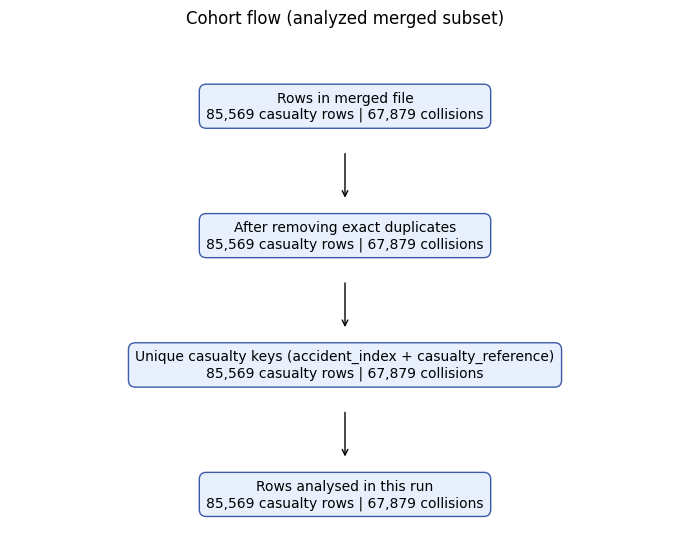

In [9]:
# %% [4] AUDIT PROVENANCE & COHORT (§3.2)
chk = []
def add_check(name, value, note=''): chk.append(dict(check=name, value=value, note=note))
key_cas = ['accident_index', 'casualty_reference']
add_check('Rows in merged file', N_FILE_ROWS)
add_check('Unique collisions (accident_index)', N_FILE_COLL)
add_check('Exact duplicate rows', int(df.duplicated().sum()), 'Tidak adanya duplikat baris tidak membuktikan join benar')
add_check('Duplicate key (accident_index, casualty_reference)', int(df.duplicated(key_cas).sum()), '0 = satu casualty satu baris')
add_check('Duplicate key (accident_index, vehicle_reference, casualty_reference)',
          int(df.duplicated(['accident_index', 'vehicle_reference', 'casualty_reference']).sum()))
same_ref = (df['accident_reference'] == df['accident_reference_veh']) & (df['accident_reference'] == df['accident_reference_cas'])
same_yr = (df['accident_year'] == df['accident_year_veh']) & (df['accident_year'] == df['accident_year_cas'])
add_check('Rows with consistent accident_reference across collision/vehicle/casualty parts', int(same_ref.sum()), f'dari {len(df)}')
add_check('Rows with consistent accident_year across parts', int(same_yr.sum()), f'dari {len(df)}')
cc = df.groupby('accident_index').agg(n_rows=('casualty_reference', 'size'), n_cas=('number_of_casualties', 'first'),
                                      n_veh=('number_of_vehicles', 'first'), n_veh_obs=('vehicle_reference', 'nunique'))
add_check('Collisions where rows == number_of_casualties (casualty-complete)', int((cc.n_rows == cc.n_cas).sum()), f'dari {len(cc)} collision')
add_check('Collisions with fewer rows than number_of_casualties', int((cc.n_rows < cc.n_cas).sum()))
add_check('Collisions with more rows than number_of_casualties (indikasi fan-out join)', int((cc.n_rows > cc.n_cas).sum()))
add_check('Collisions with distinct vehicle_reference > number_of_vehicles', int((cc.n_veh_obs > cc.n_veh).sum()))
COLL_LEVEL = ['accident_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'time', 'police_force',
              'speed_limit', 'road_type', 'light_conditions', 'weather_conditions', 'road_surface_conditions',
              'urban_or_rural_area', 'first_road_class', 'junction_detail']
nun = df.groupby('accident_index')[COLL_LEVEL].nunique()
add_check('Collision-level columns that vary within a collision (jumlah collision, total)', int((nun > 1).sum().sum()), '0 = atribut collision konsisten')
drv = df[df.casualty_class == 1]
add_check('Driver/rider casualties: age_of_casualty == age_of_driver', f'{(drv.age_of_casualty == drv.age_of_driver).mean():.4f}', 'uji kecocokan join casualty–vehicle')
add_check('Driver/rider casualties: sex_of_casualty == sex_of_driver', f'{(drv.sex_of_casualty == drv.sex_of_driver).mean():.4f}')
ped = df[df.casualty_class == 3]
add_check('Pedestrian casualties (casualty_class=3)', len(ped), 'Atribut kendaraan pada baris pedestrian merujuk ke kendaraan lain; jelaskan aturan join & relevansi fitur kendaraan')
add_check('Rows with missing coordinates (native NaN)', int(df['latitude'].isna().sum()))
save_table(pd.DataFrame(chk), 'A1_join_integrity_checks', 'A1. Audit integritas join & key')

n_dup = int(df.duplicated().sum()); n_key = int((~df.duplicated(key_cas)).sum())
flow = pd.DataFrame([
    dict(stage='Rows in merged file', n_casualty_rows=N_FILE_ROWS, n_collisions=N_FILE_COLL),
    dict(stage='After removing exact duplicates', n_casualty_rows=N_FILE_ROWS - n_dup, n_collisions=N_FILE_COLL),
    dict(stage='Unique casualty keys (accident_index + casualty_reference)', n_casualty_rows=n_key, n_collisions=N_FILE_COLL),
    dict(stage='Rows analysed in this run', n_casualty_rows=len(df), n_collisions=df['accident_index'].nunique()),
])
save_table(flow, 'A2_cohort_flow', 'A2. Alur cohort (jumlah baris tiap tahap)')
fig, ax = plt.subplots(figsize=(7, 5.5)); ax.axis('off')
for i, r in flow.iterrows():
    y0 = 0.85 - i * 0.26
    ax.text(0.5, y0, f"{r.stage}\n{r.n_casualty_rows:,} casualty rows | {r.n_collisions:,} collisions", ha='center', va='center',
            fontsize=10, bbox=dict(boxstyle='round,pad=0.5', fc='#e8f0fe', ec='#3b5ba9'))
    if i < len(flow) - 1: ax.annotate('', xy=(0.5, y0 - 0.19), xytext=(0.5, y0 - 0.09), arrowprops=dict(arrowstyle='->'))
ax.set_title('Cohort flow (analyzed merged subset)'); savefig('fig01_cohort_flow')


B1. Cross-tab enhanced_casualty_severity × casualty_severity


casualty_severity,enhanced_casualty_severity,1,2,3,All
0,-1,458,7118,39040,46616
1,1,565,0,0,565
2,3,0,0,29132,29132
3,5,0,1601,0,1601
4,6,0,2104,0,2104
5,7,0,5551,0,5551
6,All,1023,16374,68172,85569



B2. Rekonsiliasi label (kode −1 tidak otomatis non-fatal)


,item,value,pct
0,Rows with enhanced_casualty_severity = -1 (cod...,46616,54.477673
1,of which fatal by standard casualty_severity...,458,0.982495
2,of which serious (=2),7118,15.269435
3,of which slight (=3),39040,83.748069
4,Fatal by enhanced severity (=1) [pendekatan awal],565,0.660286
5,Fatal by reconciled label (utama),1023,1.195526
6,Contradictions: enhanced known but fatal-statu...,0,0.000000
7,Reconciled label identical to casualty_severit...,1,NaN



B3. Distribusi kelas menurut definisi label


,label,n_rows,n_fatal,n_nonfatal,prevalence_pct,imbalance_ratio
0,"A: enhanced==1, semua −1 -> non-fatal (pendeka...",85569,565,85004,0.660286,150.449558
1,B: reconciled (UTAMA),85569,1023,84546,1.195526,82.645161
2,C: complete-case (baris −1 dikeluarkan),38953,565,38388,1.450466,67.943363



B4. Kode −1 menurut police_force (indikasi ketiadaan struktural, bukan non-fatal)


,police_force,n,share_enh_unavailable,fatal_enhanced,fatal_reconciled,fatal_recovered_by_reconciliation
0,1,26023,0.998770,0,102,102
9,20,6434,0.000000,44,44,0
5,13,5452,0.000367,51,51,0
29,99,3896,0.000000,103,103,0
2,4,3753,0.000000,36,36,0
21,52,2981,0.999665,0,47,47
6,14,2894,0.000000,39,39,0
7,16,2512,0.000000,35,35,0
14,31,2441,0.000410,28,28,0
13,30,2264,0.999558,0,34,34


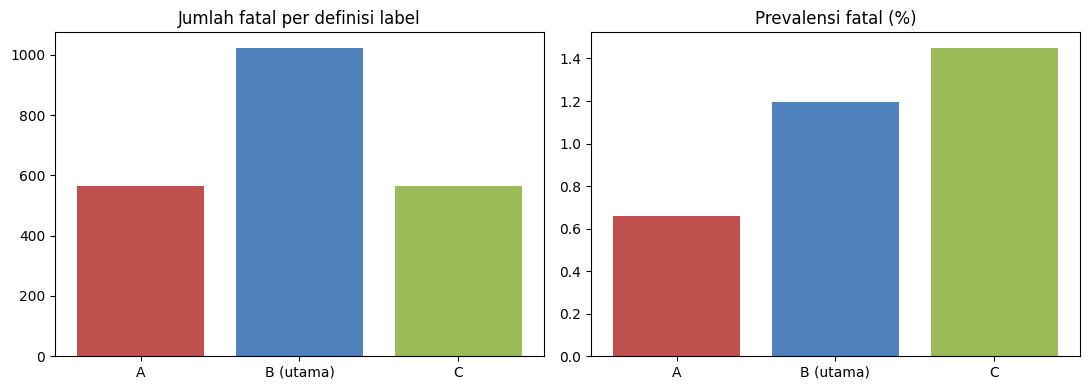


A3. Subset vs rujukan nasional (angka rujukan dari manuskrip; verifikasi ke sumber DfT). Gunakan "Great Britain" secara konsisten.


,metric,analysed_subset,national_reference,coverage_pct
0,Casualty rows,85569,132977,64.348722
1,Fatal (reconciled label B),1023,1624,62.992611
2,"Fatal (enhanced==1, pendekatan awal)",565,1624,34.790640


,metric,analysed_subset,national_reference,coverage_pct
0,Casualty rows,85569,132977,64.348722
1,Fatal (reconciled label B),1023,1624,62.992611
2,"Fatal (enhanced==1, pendekatan awal)",565,1624,34.790640


In [10]:
# %% [5] AUDIT & KONSTRUKSI LABEL TARGET (§3.1)
enh, std_sev = df['enhanced_casualty_severity'], df['casualty_severity']
xt = pd.crosstab(enh.rename('enhanced_casualty_severity'), std_sev.rename('casualty_severity'), margins=True).reset_index()
save_table(xt, 'B1_crosstab_enhanced_vs_standard', 'B1. Cross-tab enhanced_casualty_severity × casualty_severity')

n_m1 = int((enh == -1).sum()); n_m1_fatal = int(((enh == -1) & (std_sev == 1)).sum())
n_enh_fatal = int((enh == 1).sum())
# Aturan rekonsiliasi: (1) enhanced tersedia (!= -1) -> fatal iff enhanced == 1 ; (2) enhanced = -1 (coded unavailable)
# -> gunakan casualty_severity standar (1 = fatal). Kode -1 TIDAK otomatis dianggap non-fatal.
y_A = (enh == 1).astype(int).values                                   # pendekatan awal manuskrip
y_B = np.where(enh != -1, (enh == 1).astype(int), (std_sev == 1).astype(int)).astype(int)   # label tervalidasi (utama)
y_C = np.where(enh != -1, (enh == 1).astype(int), -1)                 # complete-case (kode -1 dikeluarkan)
df['y_A'], df['y_B'], df['y_C'] = y_A, y_B, y_C
df['label_source'] = np.where(enh != -1, 'enhanced_severity', 'standard_severity_fallback')
contradict = int(((enh != -1) & ((enh == 1).astype(int) != (std_sev == 1).astype(int))).sum())
rec = pd.DataFrame([
    dict(item='Rows with enhanced_casualty_severity = -1 (coded unavailable)', value=n_m1, pct=100 * n_m1 / len(df)),
    dict(item='  of which fatal by standard casualty_severity (=1)', value=n_m1_fatal, pct=100 * n_m1_fatal / max(n_m1, 1)),
    dict(item='  of which serious (=2)', value=int(((enh == -1) & (std_sev == 2)).sum()), pct=100 * ((enh == -1) & (std_sev == 2)).sum() / max(n_m1, 1)),
    dict(item='  of which slight (=3)', value=int(((enh == -1) & (std_sev == 3)).sum()), pct=100 * ((enh == -1) & (std_sev == 3)).sum() / max(n_m1, 1)),
    dict(item='Fatal by enhanced severity (=1) [pendekatan awal]', value=n_enh_fatal, pct=100 * n_enh_fatal / len(df)),
    dict(item='Fatal by reconciled label (utama)', value=int(y_B.sum()), pct=100 * y_B.mean()),
    dict(item='Contradictions: enhanced known but fatal-status differs from standard', value=contradict, pct=0.0),
    dict(item='Reconciled label identical to casualty_severity==1', value=int((y_B == (std_sev == 1).astype(int)).all()), pct=np.nan),
])
save_table(rec, 'B2_label_reconciliation', 'B2. Rekonsiliasi label (kode −1 tidak otomatis non-fatal)')

dist = []
for nm, yy, mask in [('A: enhanced==1, semua −1 -> non-fatal (pendekatan awal)', y_A, np.ones(len(df), bool)),
                     ('B: reconciled (UTAMA)', y_B, np.ones(len(df), bool)),
                     ('C: complete-case (baris −1 dikeluarkan)', y_C, y_C != -1)]:
    yy = yy[mask]; npos = int(yy.sum()); nneg = int(len(yy) - npos)
    dist.append(dict(label=nm, n_rows=int(mask.sum()), n_fatal=npos, n_nonfatal=nneg, prevalence_pct=100 * npos / len(yy),
                     imbalance_ratio=nneg / max(npos, 1)))
save_table(pd.DataFrame(dist), 'B3_class_distribution_by_label', 'B3. Distribusi kelas menurut definisi label')

pf = df.groupby('police_force').agg(n=('row_id', 'size'), share_enh_unavailable=('enhanced_casualty_severity', lambda s: (s == -1).mean()),
                                    fatal_enhanced=('y_A', 'sum'), fatal_reconciled=('y_B', 'sum')).reset_index()
pf['fatal_recovered_by_reconciliation'] = pf['fatal_reconciled'] - pf['fatal_enhanced']
pf = pf.sort_values('n', ascending=False)
save_table(pf, 'B4_enhanced_unavailable_by_police_force', 'B4. Kode −1 menurut police_force (indikasi ketiadaan struktural, bukan non-fatal)')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
d3 = pd.DataFrame(dist)
ax[0].bar(['A', 'B (utama)', 'C'], d3['n_fatal'], color=['#c0504d', '#4f81bd', '#9bbb59']); ax[0].set_title('Jumlah fatal per definisi label')
ax[1].bar(['A', 'B (utama)', 'C'], d3['prevalence_pct'], color=['#c0504d', '#4f81bd', '#9bbb59']); ax[1].set_title('Prevalensi fatal (%)')
savefig('fig02_label_distribution')

NAT = pd.DataFrame([
    dict(metric='Casualty rows', analysed_subset=len(df), national_reference=NATIONAL_REF['casualty'], coverage_pct=100 * len(df) / NATIONAL_REF['casualty']),
    dict(metric='Fatal (reconciled label B)', analysed_subset=int(y_B.sum()), national_reference=NATIONAL_REF['fatal'], coverage_pct=100 * y_B.sum() / NATIONAL_REF['fatal']),
    dict(metric='Fatal (enhanced==1, pendekatan awal)', analysed_subset=n_enh_fatal, national_reference=NATIONAL_REF['fatal'], coverage_pct=100 * n_enh_fatal / NATIONAL_REF['fatal']),
])
save_table(NAT, 'A3_subset_vs_national_reference', 'A3. Subset vs rujukan nasional (angka rujukan dari manuskrip; verifikasi ke sumber DfT). Gunakan "Great Britain" secara konsisten.')

In [11]:
# %% [6] CODED MISSINGNESS (native NaN vs kode −1) + FEATURE DICTIONARY + AVAILABILITY (§3.4, §4.2, §6)
rows = []
for c in df.columns:
    if c in ('row_id', 'y_A', 'y_B', 'y_C', 'label_source'): continue
    s = df[c]
    n_nan = int(s.isna().sum())
    n_m1c = int((s.astype(str) == '-1').sum()) if s.dtype == object or str(s.dtype).startswith('str') else int((s == -1).sum())
    rows.append(dict(variable=c, native_NaN=n_nan, native_NaN_pct=100 * n_nan / len(df), coded_minus1=n_m1c, coded_minus1_pct=100 * n_m1c / len(df)))
miss_tab = pd.DataFrame(rows).sort_values(['coded_minus1', 'native_NaN'], ascending=False)
save_table(miss_tab, 'C1_native_vs_coded_missingness', 'C1. Missingness native (NaN) vs coded (−1) dilaporkan terpisah')

# --- Definisi fitur menurut MAKNA (bukan dtype) ---
CONT_LIN = ['latitude', 'longitude', 'age_of_driver', 'age_of_casualty']
CONT_LOG = ['number_of_vehicles', 'number_of_casualties', 'engine_capacity_cc', 'age_of_vehicle']      # log1p + min-max
ORD_COLS = ['speed_limit', 'age_band_of_driver', 'age_band_of_casualty', 'driver_imd_decile', 'casualty_imd_decile',
            'driver_distance_banding', 'casualty_distance_banding']
DERIVED  = ['hour_sin', 'hour_cos', 'month_sin', 'month_cos']
BIN_COLS = ['escooter_flag']
NOM_COLS = ['police_force', 'day_of_week', 'first_road_class', 'road_type', 'junction_detail', 'junction_control',
            'second_road_class', 'pedestrian_crossing_human_control', 'pedestrian_crossing_physical_facilities',
            'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site',
            'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag',
            'vehicle_type', 'towing_and_articulation', 'vehicle_manoeuvre', 'vehicle_direction_from', 'vehicle_direction_to',
            'vehicle_location_restricted_lane', 'junction_location', 'skidding_and_overturning', 'hit_object_in_carriageway',
            'vehicle_leaving_carriageway', 'hit_object_off_carriageway', 'first_point_of_impact', 'vehicle_left_hand_drive',
            'journey_purpose_of_driver', 'sex_of_driver', 'propulsion_code', 'driver_home_area_type', 'casualty_class',
            'sex_of_casualty', 'pedestrian_location', 'pedestrian_movement', 'car_passenger', 'bus_or_coach_passenger',
            'pedestrian_road_maintenance_worker', 'casualty_type', 'casualty_home_area_type']
MISS_CODE_COLS = ['age_of_driver', 'age_of_casualty', 'engine_capacity_cc', 'age_of_vehicle', 'age_band_of_driver',
                  'age_band_of_casualty', 'driver_imd_decile', 'casualty_imd_decile', 'driver_distance_banding', 'casualty_distance_banding']
MISS_IND = {'miss_driver_age': ['age_of_driver', 'age_band_of_driver'], 'miss_casualty_age': ['age_of_casualty', 'age_band_of_casualty'],
            'miss_vehicle_age': ['age_of_vehicle'], 'miss_engine_cc': ['engine_capacity_cc'],
            'miss_driver_imd': ['driver_imd_decile'], 'miss_casualty_imd': ['casualty_imd_decile'],
            'miss_driver_dist': ['driver_distance_banding'], 'miss_casualty_dist': ['casualty_distance_banding']}
# Tier ketersediaan (ASUMSI penulis kode; peneliti perlu memvalidasi): T1 konteks sebelum/saat kejadian dilaporkan,
# T2 informasi laporan awal (panggilan darurat), T3 catatan polisi lengkap pasca-investigasi.
T1 = ['latitude', 'longitude', 'police_force', 'day_of_week', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'speed_limit',
      'first_road_class', 'road_type', 'junction_detail', 'junction_control', 'second_road_class',
      'pedestrian_crossing_human_control', 'pedestrian_crossing_physical_facilities', 'light_conditions', 'weather_conditions',
      'road_surface_conditions', 'urban_or_rural_area', 'trunk_road_flag']
T2 = ['number_of_vehicles', 'vehicle_type', 'special_conditions_at_site', 'carriageway_hazards', 'casualty_class', 'sex_of_casualty',
      'age_of_casualty', 'age_band_of_casualty', 'casualty_type', 'car_passenger', 'bus_or_coach_passenger',
      'pedestrian_road_maintenance_worker', 'miss_casualty_age']
TIER = {c: 'T1_context' for c in T1}; TIER.update({c: 'T2_early_report' for c in T2})
for c in CONT_LIN + CONT_LOG + ORD_COLS + BIN_COLS + NOM_COLS + list(MISS_IND):
    TIER.setdefault(c, 'T3_post_investigation')
SETTINGS = {'PRE_COLLISION (T1)': ['T1_context'], 'EARLY_INFO (T1+T2)': ['T1_context', 'T2_early_report'],
            'RETRO_FULL (T1+T2+T3) [utama]': ['T1_context', 'T2_early_report', 'T3_post_investigation']}

fd = []
def fd_add(var, role, transform, included, note=''):
    fd.append(dict(variable=var, role=role, transformation=transform, availability_tier=TIER.get(var, '-'),
                   included_in_models=included, note=note))
for c in CONT_LIN: fd_add(c, 'continuous', 'median impute + min-max (fit di training)', True, 'coded −1 -> NaN + indikator' if c in MISS_CODE_COLS else '')
for c in CONT_LOG: fd_add(c, 'continuous (skewed/count)', 'log1p + median impute + min-max', True, 'coded −1 -> NaN + indikator' if c in MISS_CODE_COLS else '')
for c in ORD_COLS: fd_add(c, 'ordinal', 'coded −1 -> NaN, median impute + min-max' if c in MISS_CODE_COLS else 'min-max', True)
for c in DERIVED: fd_add(c, 'continuous (derived cyclic from date/time)', 'sin/cos', True)
for c in BIN_COLS: fd_add(c, 'binary', 'passthrough (kategorik pada SMOTENC)', True)
for c in MISS_IND: fd_add(c, 'binary (coded-missingness indicator)', 'passthrough (kategorik pada SMOTENC)', True, 'rekayasa dari kode −1')
for c in NOM_COLS: fd_add(c, 'nominal (kode STATS19)', 'ordinal-code untuk SMOTENC -> one-hot (kategori jarang digabung); −1 & 9/99 = kategori "unknown"', True)
EXCL = {
 'accident_index': ('identifier / GROUP', 'dipakai sebagai groups pada grouped CV, BUKAN prediktor'),
 'accident_year': ('identifier', 'konstan/identifier'), 'accident_reference': ('identifier', ''), 'accident_year_veh': ('identifier', ''),
 'accident_reference_veh': ('identifier', ''), 'accident_year_cas': ('identifier', ''), 'accident_reference_cas': ('identifier', ''),
 'vehicle_reference': ('identifier', 'nomor urut kendaraan'), 'casualty_reference': ('identifier', 'nomor urut casualty'),
 'accident_severity': ('outcome proxy', 'severity collision memuat informasi fatal casualty -> dikeluarkan'),
 'enhanced_severity_collision': ('outcome proxy', 'dikeluarkan'), 'casualty_severity': ('outcome source/proxy', 'sumber label -> dikeluarkan'),
 'enhanced_casualty_severity': ('target source', 'sumber label -> dikeluarkan'),
 'location_easting_osgr': ('redundant', 'duplikat informasi latitude/longitude'), 'location_northing_osgr': ('redundant', 'duplikat latitude/longitude'),
 'local_authority_district': ('constant', 'konstan (−1)'), 'local_authority_ons_district': ('high-cardinality geographic code', '231 level'),
 'local_authority_highway': ('high-cardinality geographic code', '157 level'), 'lsoa_of_accident_location': ('high-cardinality geographic code', ''),
 'lsoa_of_driver': ('high-cardinality geographic code', ''), 'lsoa_of_casualty': ('high-cardinality geographic code', ''),
 'generic_make_model': ('high-cardinality text', '684 level, banyak −1'), 'first_road_number': ('identifier (nomor jalan)', ''),
 'second_road_number': ('identifier (nomor jalan)', ''), 'dir_from_e': ('sparse (>90% NaN)', ''), 'dir_from_n': ('sparse (>90% NaN)', ''),
 'dir_to_e': ('sparse (>90% NaN)', ''), 'dir_to_n': ('sparse (>90% NaN)', ''),
 'date': ('raw -> derived', 'diturunkan menjadi month (sin/cos)'), 'time': ('raw -> derived', 'diturunkan menjadi hour (sin/cos)'),
}
for c, (role, note) in EXCL.items(): fd_add(c, role, '-', False, note)
FEATURE_DICT = pd.DataFrame(fd)
missing_in_dict = set(df.columns) - set(FEATURE_DICT.variable) - {'row_id', 'y_A', 'y_B', 'y_C', 'label_source'}
assert not missing_in_dict, f'Kolom belum terdokumentasi: {missing_in_dict}'
save_table(FEATURE_DICT, 'C2_feature_dictionary', 'C2. Feature dictionary (kontinu/biner/ordinal/nominal/identifier/coded-missingness/proxy)')
avail = FEATURE_DICT[FEATURE_DICT.included_in_models].groupby('availability_tier').variable.apply(lambda s: ', '.join(s)).reset_index()
save_table(avail, 'C3_feature_availability_by_prediction_setting', 'C3. Audit ketersediaan fitur menurut waktu prediksi (asumsi; validasi oleh peneliti)')
print('\nSETTING UTAMA: RETRO_FULL = klasifikasi retrospektif dari catatan polisi lengkap -> JANGAN diklaim sebagai triase real-time.')
print('Sensitivitas: PRE_COLLISION dan EARLY_INFO (lihat bagian sensitivitas).')


C1. Missingness native (NaN) vs coded (−1) dilaporkan terpisah


,variable,native_NaN,native_NaN_pct,coded_minus1,coded_minus1_pct
14,local_authority_district,0,0.000000,85569,100.000000
36,enhanced_severity_collision,0,0.000000,46616,54.477673
87,enhanced_casualty_severity,0,0.000000,46616,54.477673
22,junction_control,0,0.000000,33392,39.023478
24,second_road_number,0,0.000000,33120,38.705606
60,generic_make_model,0,0.000000,21735,25.400554
57,engine_capacity_cc,0,0.000000,20581,24.051935
59,age_of_vehicle,0,0.000000,19267,22.516332
58,propulsion_code,0,0.000000,19244,22.489453
63,lsoa_of_driver,0,0.000000,14170,16.559735



C2. Feature dictionary (kontinu/biner/ordinal/nominal/identifier/coded-missingness/proxy)


,variable,role,transformation,availability_tier,included_in_models,note
0,latitude,continuous,median impute + min-max (fit di training),T1_context,True,
1,longitude,continuous,median impute + min-max (fit di training),T1_context,True,
2,age_of_driver,continuous,median impute + min-max (fit di training),T3_post_investigation,True,coded −1 -> NaN + indikator
3,age_of_casualty,continuous,median impute + min-max (fit di training),T2_early_report,True,coded −1 -> NaN + indikator
4,number_of_vehicles,continuous (skewed/count),log1p + median impute + min-max,T2_early_report,True,
5,number_of_casualties,continuous (skewed/count),log1p + median impute + min-max,T3_post_investigation,True,
6,engine_capacity_cc,continuous (skewed/count),log1p + median impute + min-max,T3_post_investigation,True,coded −1 -> NaN + indikator
7,age_of_vehicle,continuous (skewed/count),log1p + median impute + min-max,T3_post_investigation,True,coded −1 -> NaN + indikator
8,speed_limit,ordinal,min-max,T1_context,True,
9,age_band_of_driver,ordinal,"coded −1 -> NaN, median impute + min-max",T3_post_investigation,True,



C3. Audit ketersediaan fitur menurut waktu prediksi (asumsi; validasi oleh peneliti)


,availability_tier,variable
0,T1_context,"latitude, longitude, speed_limit, hour_sin, ho..."
1,T2_early_report,"age_of_casualty, number_of_vehicles, age_band_..."
2,T3_post_investigation,"age_of_driver, number_of_casualties, engine_ca..."



SETTING UTAMA: RETRO_FULL = klasifikasi retrospektif dari catatan polisi lengkap -> JANGAN diklaim sebagai triase real-time.
Sensitivitas: PRE_COLLISION dan EARLY_INFO (lihat bagian sensitivitas).


In [12]:
# %% [7] MATRIKS FITUR (semantic & naive) + spesifikasi per setting
def build_semantic_X(d):
    X = pd.DataFrame(index=d.index)
    dt = pd.to_datetime(d['date'], format='%d/%m/%Y', errors='coerce')
    hour = pd.to_numeric(d['time'].astype(str).str.slice(0, 2), errors='coerce'); month = dt.dt.month
    X['hour_sin'] = np.sin(2 * np.pi * hour / 24); X['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    X['month_sin'] = np.sin(2 * np.pi * month / 12); X['month_cos'] = np.cos(2 * np.pi * month / 12)
    for c in CONT_LIN + CONT_LOG + ORD_COLS:
        v = pd.to_numeric(d[c], errors='coerce').astype(float)
        if c in MISS_CODE_COLS: v = v.where(v != -1)
        if c in CONT_LOG: v = np.log1p(v)
        X[c] = v
    for ind, cols in MISS_IND.items():
        X[ind] = np.any([(d[c] == -1).values for c in cols], axis=0).astype(float)
    for c in BIN_COLS: X[c] = d[c].astype(float)
    for c in NOM_COLS: X[c] = d[c].astype(int)
    return X

def build_naive_X(d):   # representasi "dtype-based" seperti manuskrip: semua kode sebagai angka apa adanya
    X = pd.DataFrame(index=d.index)
    for c in CONT_LIN + CONT_LOG + ORD_COLS + BIN_COLS + NOM_COLS: X[c] = pd.to_numeric(d[c], errors='coerce').astype(float)
    X['hour'] = pd.to_numeric(d['time'].astype(str).str.slice(0, 2), errors='coerce')
    X['month'] = pd.to_datetime(d['date'], format='%d/%m/%Y', errors='coerce').dt.month
    return X

X_SEM, X_NAIVE = build_semantic_X(df), build_naive_X(df)
TIER.update({'hour': 'T1_context', 'month': 'T1_context'})

def make_spec(tiers):
    keep = lambda cols: [c for c in cols if TIER[c] in tiers]
    spec = dict(num=keep(CONT_LIN + CONT_LOG + ORD_COLS + DERIVED), bin=keep(BIN_COLS + list(MISS_IND)), nom=keep(NOM_COLS))
    spec['naive'] = keep(CONT_LIN + CONT_LOG + ORD_COLS + BIN_COLS + NOM_COLS + ['hour', 'month'])
    return spec
SPEC_FULL = make_spec(SETTINGS['RETRO_FULL (T1+T2+T3) [utama]'])
print('Fitur (semantic) utama: numerik/ordinal =', len(SPEC_FULL['num']), '| biner+indikator =', len(SPEC_FULL['bin']), '| nominal =', len(SPEC_FULL['nom']))
GROUPS = df['accident_index'].values
Y_MAIN = df['y_B'].values.astype(int)

Fitur (semantic) utama: numerik/ordinal = 19 | biner+indikator = 9 | nominal = 43



D1. Komposisi fold (collision-grouped): jumlah collision & fatal per fold


,fold,test_rows,test_collisions,test_fatal,test_collisions_with_fatal,train_rows,train_collisions,train_fatal,collisions_shared_train_test
0,0,17012,13570,190,184,68557,54309,833,0
1,1,17079,13577,206,194,68490,54302,817,0
2,2,17163,13572,212,196,68406,54307,811,0
3,3,17209,13591,223,204,68360,54288,800,0
4,4,17106,13569,192,179,68463,54310,831,0



D2. Row-wise CV: baris uji yang collision-nya juga ada di training


,fold,test_rows,test_rows_whose_collision_also_in_train,pct
0,0,17114,5147,30.074793
1,1,17114,5186,30.302676
2,2,17114,5158,30.139067
3,3,17114,5133,29.992988
4,4,17113,5200,30.386256


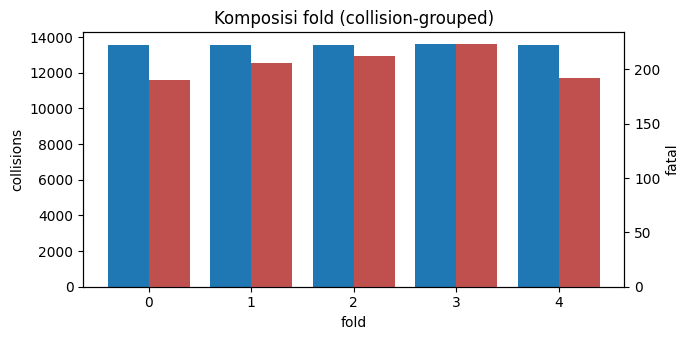

In [13]:
# %% [8] DESAIN VALIDASI: collision-grouped stratified CV (§3.3)
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
FOLD_MAIN = np.full(len(df), -1)
for k, (tr, te) in enumerate(sgkf.split(np.zeros(len(df)), Y_MAIN, GROUPS)): FOLD_MAIN[te] = k
fc = []
for k in range(N_SPLITS):
    te, tr = FOLD_MAIN == k, FOLD_MAIN != k
    overlap = len(set(GROUPS[te]) & set(GROUPS[tr]))
    assert overlap == 0, 'Collision overlap train/test terdeteksi!'
    fc.append(dict(fold=k, test_rows=int(te.sum()), test_collisions=len(set(GROUPS[te])), test_fatal=int(Y_MAIN[te].sum()),
                   test_collisions_with_fatal=len(set(GROUPS[te & (Y_MAIN == 1)])), train_rows=int(tr.sum()),
                   train_collisions=len(set(GROUPS[tr])), train_fatal=int(Y_MAIN[tr].sum()), collisions_shared_train_test=overlap))
save_table(pd.DataFrame(fc), 'D1_fold_composition_grouped_cv', 'D1. Komposisi fold (collision-grouped): jumlah collision & fatal per fold')
# Row-wise CV (pembanding, hanya untuk sensitivitas S2): ukur seberapa sering collision melintasi train/test
FOLD_ROW = np.full(len(df), -1)
for k, (tr, te) in enumerate(StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(np.zeros(len(df)), Y_MAIN)): FOLD_ROW[te] = k
ov = []
for k in range(N_SPLITS):
    te, tr = FOLD_ROW == k, FOLD_ROW != k
    gt, gr = GROUPS[te], set(GROUPS[tr])
    ov.append(dict(fold=k, test_rows=int(te.sum()), test_rows_whose_collision_also_in_train=int(np.isin(gt, list(gr)).sum()),
                   pct=100 * np.isin(gt, list(gr)).mean()))
save_table(pd.DataFrame(ov), 'D2_rowwise_cv_collision_overlap', 'D2. Row-wise CV: baris uji yang collision-nya juga ada di training')
fig, ax = plt.subplots(figsize=(7, 3.5)); fcd = pd.DataFrame(fc)
ax.bar(fcd.fold - 0.2, fcd.test_collisions, 0.4, label='collisions (test)'); ax2 = ax.twinx()
ax2.bar(fcd.fold + 0.2, fcd.test_fatal, 0.4, color='#c0504d', label='fatal (test)'); ax.set_xlabel('fold'); ax.set_ylabel('collisions'); ax2.set_ylabel('fatal')
ax.set_title('Komposisi fold (collision-grouped)'); savefig('fig03_fold_composition')

In [14]:
# %% [9] MESIN EKSPERIMEN: representasi per-fold (tanpa leakage), sampler, classifier
SAMPLERS_MAIN = ['None', 'RUS', 'NearMiss', 'SMOTENC', 'SMOTENC+Tomek', 'SMOTENC+ENN']
CLASSIFIERS   = ['LR', 'LinearSVC', 'RF', 'HGB']
CW = 'ClassWeight'
WARN_LOG, FAIL_LOG = [], []

def _mk(cls, **kw):
    try: return cls(**kw)
    except TypeError:
        kw.pop('n_jobs', None); return cls(**kw)

def make_prep(spec):
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', MinMaxScaler())]), spec['num']),
        ('bin', 'passthrough', spec['bin']),
        ('nom', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), spec['nom']),
    ], sparse_threshold=0)

def make_encoder(n_pass, n_nom):
    return ColumnTransformer([
        ('keep', 'passthrough', list(range(n_pass))),
        ('ohe', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=OHE_MIN_FREQ, sparse_output=False, dtype=np.float32),
         list(range(n_pass, n_pass + n_nom))),
    ], sparse_threshold=0)

def _cnt(y): b = np.bincount(np.asarray(y).astype(int), minlength=2); return int(b[0]), int(b[1])

class RepFactory:
    """Semua langkah (imputasi, scaling, encoding, resampling) di-fit HANYA pada data latih tahap ini."""
    def __init__(self, X, y, tr, ev, spec, kind, seed, tag, fold, stage, stage_log):
        self.y, self.tr, self.ev, self.spec, self.kind, self.seed = y, tr, ev, spec, kind, seed
        self.tag, self.fold, self.stage, self.log = tag, fold, stage, stage_log
        self.ytr = y[tr]; self._smote = None
        t0 = time.perf_counter()
        if kind == 'semantic':
            self.prep = make_prep(spec)
            self.P_tr = self.prep.fit_transform(X.iloc[tr]); self.P_ev = {k: self.prep.transform(X.iloc[v]) for k, v in ev.items()}
            self.n_num = len(spec['num']); self.n_pass = self.n_num + len(spec['bin']); self.n_nom = len(spec['nom'])
            self.cat_idx = list(range(self.n_num, self.n_pass + self.n_nom))
            for k, P in self.P_ev.items():      # klaim "min-max selalu [0,1]" hanya berlaku di training (§6)
                blk = P[:, :self.n_num]; oor = float(((blk < -1e-9) | (blk > 1 + 1e-9)).mean())
                self.log.append(dict(tag=tag, fold=fold, stage=stage, sampler='(prep)', step=f'{k}: share numeric cells outside training [0,1]',
                                     n_rows=len(P), n_features=self.n_num, n_nonfatal=np.nan, n_fatal=np.nan, value=oor, seconds=np.nan))
            self.enc = make_encoder(self.n_pass, self.n_nom)
            self.E_tr = self.enc.fit_transform(self.P_tr).astype(np.float32)
            self.E_ev = {k: self.enc.transform(P).astype(np.float32) for k, P in self.P_ev.items()}
        else:
            self.prep = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', MinMaxScaler())])
            self.P_tr = self.prep.fit_transform(X.iloc[tr][spec['naive']])
            self.E_tr = self.P_tr.astype(np.float32)
            self.E_ev = {k: self.prep.transform(X.iloc[v][spec['naive']]).astype(np.float32) for k, v in ev.items()}
        self._rec('(prep)', 'after prep+encoding (no resampling)', self.E_tr, self.ytr, time.perf_counter() - t0)

    def _rec(self, sampler, step, Xm, ym, secs):
        n0, n1 = _cnt(ym)
        self.log.append(dict(tag=self.tag, fold=self.fold, stage=self.stage, sampler=sampler, step=step, n_rows=len(ym),
                             n_features=Xm.shape[1], n_nonfatal=n0, n_fatal=n1, value=np.nan, seconds=secs))

    def get(self, name):
        t0 = time.perf_counter()
        if name in ('None', CW):
            Xtr, ytr, ev = self.E_tr, self.ytr, self.E_ev
        elif name == 'RUS':
            Xtr, ytr = RandomUnderSampler(random_state=self.seed).fit_resample(self.E_tr, self.ytr); ev = self.E_ev
        elif name == 'NearMiss':
            Xtr, ytr = _mk(NearMiss, version=1, n_neighbors=3, n_jobs=-1).fit_resample(self.E_tr, self.ytr); ev = self.E_ev
        elif name == 'SMOTE':   # SMOTE standar (hanya untuk sensitivitas encoding)
            Xtr, ytr = SMOTE(random_state=self.seed, k_neighbors=5).fit_resample(self.E_tr, self.ytr); ev = self.E_ev
        elif name.startswith('SMOTENC'):
            if self._smote is None:
                ts = time.perf_counter()
                Pres, yres = SMOTENC(categorical_features=self.cat_idx, random_state=self.seed, k_neighbors=5).fit_resample(self.P_tr, self.ytr)
                enc = make_encoder(self.n_pass, self.n_nom)
                Eres = enc.fit_transform(Pres).astype(np.float32); Eev = {k: enc.transform(self.prep_ev_for_smote(k)).astype(np.float32) for k in self.ev}
                self._smote = (Eres, np.asarray(yres), Eev, time.perf_counter() - ts)
                self._rec('SMOTENC', 'after SMOTENC + encoding', Eres, yres, self._smote[3])
            Eres, yres, Eev, t_s = self._smote
            if name == 'SMOTENC': Xtr, ytr, ev = Eres, yres, Eev
            else:   # hybrid: pembersihan (Tomek/ENN, sampling_strategy='all') pada representasi one-hot
                cl = _mk(TomekLinks, sampling_strategy='all', n_jobs=-1) if name.endswith('Tomek') else \
                     _mk(EditedNearestNeighbours, sampling_strategy='all', n_neighbors=3, n_jobs=-1)
                Xtr, ytr = cl.fit_resample(Eres, yres); ev = Eev
        else:
            raise ValueError(name)
        secs = time.perf_counter() - t0
        if name.startswith('SMOTENC') and name != 'SMOTENC': secs += self._smote[3]
        elif name == 'SMOTENC': secs = self._smote[3]
        ytr = np.asarray(ytr).astype(int)
        if name not in ('None', CW, 'SMOTENC'): self._rec(name, 'after sampler', Xtr, ytr, secs)
        return dict(Xtr=Xtr, ytr=ytr, ev=ev, resample_s=secs, n_features=Xtr.shape[1])

    def prep_ev_for_smote(self, k): return self.P_ev[k]
    def release(self): self._smote = None; self.P_tr = self.E_tr = None; gc.collect()

def make_clf(name, cw, seed):
    if name == 'LR':
        return LogisticRegression(max_iter=1000, solver='lbfgs', C=1.0, class_weight='balanced' if cw else None, random_state=seed)
    if name == 'LinearSVC':
        return LinearSVC(C=1.0, dual=False, max_iter=5000, class_weight='balanced' if cw else None, random_state=seed)
    if name == 'RF':
        return RandomForestClassifier(n_estimators=100, min_samples_leaf=3, max_features='sqrt', max_samples=0.5,
                                      class_weight='balanced_subsample' if cw else None, n_jobs=-1, random_state=seed)
    if name == 'HGB':
        return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_leaf_nodes=31, early_stopping=False,
                                              class_weight='balanced' if cw else None, random_state=seed)
    raise ValueError(name)

def get_score(name, model, X):
    return model.decision_function(X) if name == 'LinearSVC' else model.predict_proba(X)[:, 1]

def fit_and_score(clf_name, rep, cw, seed, ctx):
    """Fit satu classifier; catat warning (mis. konvergensi) dan kegagalan, tidak ditekan."""
    cfg = ctx['config']
    t0 = time.perf_counter(); out = {}
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        try:
            model = make_clf(clf_name, cw, seed); model.fit(rep['Xtr'], rep['ytr']); fit_s = time.perf_counter() - t0
            t1 = time.perf_counter()
            for k, Xe in rep['ev'].items(): out[k] = np.asarray(get_score(clf_name, model, Xe), dtype=np.float64)
            pred_s = time.perf_counter() - t1
        except Exception as e:
            FAIL_LOG.append(dict(**ctx, error=repr(e)[:300])); return None, np.nan, np.nan
    for x in w:
        WARN_LOG.append(dict(**ctx, category=x.category.__name__, message=str(x.message)[:200]))
    return out, fit_s, pred_s

def run_cv(tag, X, y, groups, fold_id, spec, kind, samplers, clfs, with_thresholds, include_cw=False):
    n = len(y); folds = sorted(np.unique(fold_id)); smp_list = list(samplers) + ([CW] if include_cw else [])
    configs = [f'{s}__{c}' for s in smp_list for c in clfs]
    oof = {c: np.full(n, np.nan) for c in configs}; val_store = {}; times, stage_log = [], []
    for k in folds:
        fp = hashlib.md5(f'{n}|{int(y.sum())}|{RANDOM_STATE}|{len(spec["num"])}|{len(spec["nom"])}|{kind}|{N_SPLITS}|{INNER_SPLITS}'.encode()).hexdigest()[:8]
        ck = os.path.join(CKPT_DIR, f'{tag}_{fp}_fold{k}.pkl'); seed = RANDOM_STATE + int(k)
        if RESUME and os.path.exists(ck):
            fr = pickle.load(open(ck, 'rb')); print(f'[{tag}] fold {k}: checkpoint dimuat')
        else:
            te = np.where(fold_id == k)[0]; tr = np.where(fold_id != k)[0]
            fr = dict(test={}, val={}, times=[], stage=[], warn=[], fail=[])
            stages = [('outer', tr, {'test': te})]
            if with_thresholds:
                itr, iva = next(StratifiedGroupKFold(INNER_SPLITS, shuffle=True, random_state=seed).split(tr, y[tr], groups[tr]))
                stages.append(('inner', tr[itr], {'val': tr[iva]}))
            nw0, nf0 = len(WARN_LOG), len(FAIL_LOG)
            for stage_name, tr_idx, ev in stages:
                fac = RepFactory(X, y, tr_idx, ev, spec, kind, seed, tag, int(k), stage_name, fr['stage'])
                for s in smp_list:
                    try: rep = fac.get(s)
                    except Exception as e:
                        FAIL_LOG.append(dict(tag=tag, fold=int(k), stage=stage_name, config=f'{s}__*', error=repr(e)[:300])); continue
                    for ci, c in enumerate(clfs):
                        cfg = f'{s}__{c}'
                        ctx = dict(tag=tag, fold=int(k), stage=stage_name, config=cfg)
                        out, fit_s, pred_s = fit_and_score(c, rep, s == CW, seed, ctx)
                        if out is None: continue
                        if stage_name == 'outer': fr['test'][cfg] = out['test']
                        else: fr['val'][cfg] = (y[ev['val']], out['val'])
                        fr['times'].append(dict(tag=tag, fold=int(k), stage=stage_name, sampler=s, classifier=c, config=cfg,
                                                resample_s=rep['resample_s'], resample_counted_s=rep['resample_s'] if ci == 0 else 0.0,
                                                fit_s=fit_s, predict_s=pred_s, n_train_rows=len(rep['ytr']), n_features=rep['n_features'],
                                                n_train_fatal=int(rep['ytr'].sum())))
                        print(f'[{tag}] fold {k} {stage_name:5s} {cfg:24s} resample {rep["resample_s"]:6.1f}s fit {fit_s:6.1f}s', flush=True)
                    del rep; gc.collect()
                fac.release(); del fac
            fr['warn'], fr['fail'] = WARN_LOG[nw0:], FAIL_LOG[nf0:]
            pickle.dump(fr, open(ck, 'wb'))
        te = np.where(fold_id == k)[0]
        for cfg, sc in fr['test'].items(): oof[cfg][te] = sc
        for cfg, v in fr['val'].items(): val_store[(int(k), cfg)] = v
        times += fr['times']; stage_log += fr['stage']
    return dict(oof=pd.DataFrame(oof), val=val_store, times=pd.DataFrame(times), stage=pd.DataFrame(stage_log), configs=configs, fold_id=fold_id)

def fold_metric_table(oof, y, fold_id, configs):
    rows = []
    for cfg in configs:
        s = oof[cfg].values
        for k in sorted(np.unique(fold_id)):
            m = fold_id == k; ys, ss = y[m], s[m]
            ok = (not np.isnan(ss).any()) and ys.sum() > 0
            r = dict(config=cfg, fold=int(k), n_test=int(m.sum()), n_fatal=int(ys.sum()), prevalence=float(ys.mean()),
                     roc_auc=roc_auc_score(ys, ss) if ok else np.nan, pr_auc=average_precision_score(ys, ss) if ok else np.nan)
            for cap in CAPACITIES:
                if ok:
                    pred = ss >= thr_capacity(ss, cap); tp, fp, fn, tn = confusion(ys, pred)
                    r[f'recall_top{int(cap * 100)}pct'] = safe_div(tp, tp + fn); r[f'precision_top{int(cap * 100)}pct'] = safe_div(tp, tp + fp)
                else: r[f'recall_top{int(cap * 100)}pct'] = r[f'precision_top{int(cap * 100)}pct'] = np.nan
            rows.append(r)
    return pd.DataFrame(rows)

def summarize(fm):
    g = fm.groupby('config')
    out = g.agg(mean_roc_auc=('roc_auc', 'mean'), sd_roc_auc_across_folds=('roc_auc', 'std'), mean_pr_auc=('pr_auc', 'mean'),
                sd_pr_auc_across_folds=('pr_auc', 'std'), **{f'mean_recall_top{int(c * 100)}pct': (f'recall_top{int(c * 100)}pct', 'mean') for c in CAPACITIES}).reset_index()
    return out.sort_values('mean_roc_auc', ascending=False).reset_index(drop=True)

In [15]:
# %% [10] EKSPERIMEN UTAMA: 24 konfigurasi × 5 fold (collision-grouped) + baseline class-weight (suplemen)
print(f'Label utama = reconciled (B). Fatal = {int(Y_MAIN.sum())} dari {len(Y_MAIN)} ({100 * Y_MAIN.mean():.3f}%).')
t_main = time.perf_counter()
MAIN = run_cv('main', X_SEM, Y_MAIN, GROUPS, FOLD_MAIN, SPEC_FULL, 'semantic', SAMPLERS_MAIN, CLASSIFIERS,
              with_thresholds=True, include_cw=RUN_CLASS_WEIGHT)
print(f'Eksperimen utama selesai dalam {(time.perf_counter() - t_main) / 60:.1f} menit.')
CFG_MAIN24 = [f'{s}__{c}' for s in SAMPLERS_MAIN for c in CLASSIFIERS]
CFG_ALL = MAIN['configs']
OOF = MAIN['oof']

# Simpan prediksi out-of-fold (seluruh observasi) -> dipakai untuk semua tabel/figur (§3.5, §7)
pred_df = pd.DataFrame({'row_id': df['row_id'], 'collision_id': GROUPS, 'fold': FOLD_MAIN, 'y_true_reconciled': Y_MAIN, 'y_original_approach': y_A})
pred_df = pd.concat([pred_df, OOF.add_prefix('score__')], axis=1)
PRED_PATH = os.path.join(PRED_DIR, 'oof_predictions_main.csv.gz'); pred_df.to_csv(PRED_PATH, index=False, compression='gzip')
print('Prediksi OOF tersimpan:', PRED_PATH)

Label utama = reconciled (B). Fatal = 1023 dari 85569 (1.196%).
[main] fold 0 outer None__LR                 resample    0.0s fit    2.9s
[main] fold 0 outer None__LinearSVC          resample    0.0s fit    5.7s
[main] fold 0 outer None__RF                 resample    0.0s fit    9.6s
[main] fold 0 outer None__HGB                resample    0.0s fit   27.0s
[main] fold 0 outer RUS__LR                  resample    0.0s fit    0.7s
[main] fold 0 outer RUS__LinearSVC           resample    0.0s fit    0.1s
[main] fold 0 outer RUS__RF                  resample    0.0s fit    0.4s
[main] fold 0 outer RUS__HGB                 resample    0.0s fit    2.8s
[main] fold 0 outer NearMiss__LR             resample    2.7s fit    0.5s
[main] fold 0 outer NearMiss__LinearSVC      resample    2.7s fit    0.1s
[main] fold 0 outer NearMiss__RF             resample    2.7s fit    0.4s
[main] fold 0 outer NearMiss__HGB            resample    2.7s fit    2.8s
[main] fold 0 outer SMOTENC__LR              res

In [16]:
# %% [11] EVALUASI UTAMA: metrik lintas konfigurasi, operating points, confusion matrix (§3.5)
FM = fold_metric_table(OOF, Y_MAIN, FOLD_MAIN, CFG_ALL)
save_table(FM, 'E1_per_fold_metrics_all_configs', 'E1. Metrik per fold, SEMUA konfigurasi (bukan fold/konfigurasi terpilih)', display_it=False)
SUM = summarize(FM)
SUM['family'] = np.where(SUM.config.str.startswith(CW), 'supplementary (class weight)', 'main (24 configs)')
pooled = []
for cfg in CFG_ALL:
    s = OOF[cfg].values
    if np.isnan(s).any(): continue
    pooled.append(dict(config=cfg, pooled_oof_roc_auc=roc_auc_score(Y_MAIN, s), pooled_oof_pr_auc=average_precision_score(Y_MAIN, s)))
SUM = SUM.merge(pd.DataFrame(pooled), on='config', how='left')
save_table(SUM, 'E2_summary_all_configs', 'E2. Ringkasan semua konfigurasi (rata-rata & SD antar-fold; pooled OOF). Prevalensi = ' + f'{100 * Y_MAIN.mean():.3f}%')

main_sum = SUM[SUM.config.isin(CFG_MAIN24)].reset_index(drop=True)
BEST_AUC = main_sum.iloc[0]['config']
print(f'\nCombination with the highest mean cross-validated ROC-AUC: {BEST_AUC} (mean ROC-AUC = {main_sum.iloc[0]["mean_roc_auc"]:.4f}). '
      'Istilah "best model" TIDAK dipakai; konfigurasi terbaik bergantung pada kriteria:')
crit = pd.DataFrame([dict(criterion=c, config=main_sum.sort_values(c, ascending=False).iloc[0]['config'], value=main_sum[c].max())
                     for c in ['mean_roc_auc', 'mean_pr_auc'] + [f'mean_recall_top{int(k * 100)}pct' for k in CAPACITIES]])
save_table(crit, 'E3_leader_by_criterion', 'E3. Konfigurasi unggul menurut kriteria berbeda')

# --- Operating points: threshold dari inner-validation; kapasitas label-free; confusion matrix ---
op_rows = []
for cfg in CFG_ALL:
    clf = cfg.split('__')[1]
    for k in range(N_SPLITS):
        m = FOLD_MAIN == k; st = OOF[cfg].values[m]; yt = Y_MAIN[m]
        if np.isnan(st).any(): continue
        yv, sv = MAIN['val'].get((k, cfg), (None, None))
        for op, thr in op_thresholds(clf, yv, sv, st).items():
            tp, fp, fn, tn = confusion(yt, st >= thr)
            op_rows.append(dict(config=cfg, fold=k, operating_point=op, threshold=float(thr), TP=tp, FP=fp, FN=fn, TN=tn))
OPF = pd.DataFrame(op_rows)
save_table(OPF, 'F1_operating_points_per_fold', 'F1. Confusion per fold per operating point', display_it=False)
pl = OPF.groupby(['config', 'operating_point'])[['TP', 'FP', 'FN', 'TN']].sum().reset_index()
met = pl.apply(lambda r: pd.Series(conf_metrics(r.TP, r.FP, r.FN, r.TN)), axis=1)
OP_POOLED = pd.concat([pl, met], axis=1)
save_table(OP_POOLED, 'F2_operating_points_pooled_oof', 'F2. Operating points (pooled OOF): recall, precision, F1, F2, MCC, balanced accuracy, confusion matrix', display_it=False)
fm_ops = OPF.copy()
met_f = fm_ops.apply(lambda r: pd.Series(conf_metrics(r.TP, r.FP, r.FN, r.TN)), axis=1)
OP_FOLDMEAN = pd.concat([fm_ops[['config', 'fold', 'operating_point']], met_f], axis=1).groupby(['config', 'operating_point']).agg(['mean', 'std']).reset_index()
OP_FOLDMEAN.columns = ['_'.join([c for c in col if c]).strip('_') for col in OP_FOLDMEAN.columns]
save_table(OP_FOLDMEAN, 'F3_operating_points_fold_mean_sd', 'F3. Operating points: rata-rata & SD antar-fold', display_it=False)
show(OP_POOLED[OP_POOLED.operating_point == 'default'][['config', 'TP', 'FP', 'FN', 'TN', 'recall', 'precision', 'MCC']].sort_values('recall', ascending=False),
     'F2a. Threshold default (0.5; LinearSVC 0.0) — deteksi fatal')
cap_cmp = OP_POOLED[OP_POOLED.config.isin(CFG_MAIN24)].pivot(index='config', columns='operating_point', values='recall')
save_table(cap_cmp.reset_index(), 'F4_recall_by_operating_point', 'F4. Recall per operating point (threshold dibandingkan pada batas operasional yang sebanding)')
prec_cmp = OP_POOLED[OP_POOLED.config.isin(CFG_MAIN24)].pivot(index='config', columns='operating_point', values='precision')
save_table(prec_cmp.reset_index(), 'F5_precision_by_operating_point', 'F5. Precision per operating point', display_it=False)

# --- Dispersi antar-metode (BUKAN stabilitas), variasi antar-split, klaim model linear, skor bertabrakan (§6) ---
piv = main_sum.assign(sampler=main_sum.config.str.split('__').str[0], clf=main_sum.config.str.split('__').str[1])
disp = pd.concat([
    piv.groupby('clf').mean_roc_auc.agg(['mean', 'std', 'min', 'max']).assign(kind='between-sampler dispersion within classifier family'),
    piv.groupby('sampler').mean_roc_auc.agg(['mean', 'std', 'min', 'max']).assign(kind='between-classifier dispersion within sampler family')]).reset_index().rename(columns={'index': 'group', 'std': 'sd_between_methods'})
save_table(disp, 'G1_between_method_dispersion', 'G1. Dispersi antarmetode (BUKAN stabilitas; variasi antar-split ada di E2: sd_*_across_folds)')
lin = piv[piv.clf.isin(['LR', 'LinearSVC'])][['config', 'mean_roc_auc']].copy()
lin['within_claimed_range'] = lin.mean_roc_auc.between(*CLAIM_LINEAR_RANGE)
save_table(lin, 'G2_audit_claim_linear_models_range', f'G2. Audit klaim "model linear selalu {CLAIM_LINEAR_RANGE[0]}–{CLAIM_LINEAR_RANGE[1]}": nyatakan pengecualian & rentang aktual')
tie = []
for cfg in CFG_ALL:
    s = OOF[cfg].values
    if np.isnan(s).any(): continue
    u, c = np.unique(s, return_counts=True)
    tie.append(dict(config=cfg, n_unique_scores=len(u), share_rows_in_tied_score_groups=float(c[c > 1].sum() / len(s))))
save_table(pd.DataFrame(tie), 'G3_score_ties_diagnostics', 'G3. Diagnostik skor bertabrakan (tied) — mekanisme RF/intercept tetap hipotesis interpretatif', display_it=False)


E2. Ringkasan semua konfigurasi (rata-rata & SD antar-fold; pooled OOF). Prevalensi = 1.196%


,config,mean_roc_auc,sd_roc_auc_across_folds,mean_pr_auc,sd_pr_auc_across_folds,mean_recall_top5pct,mean_recall_top10pct,family,pooled_oof_roc_auc,pooled_oof_pr_auc
0,None__HGB,0.871701,0.007087,0.097468,0.010731,0.368795,0.567715,main (24 configs),0.871206,0.094426
1,None__LR,0.870773,0.007586,0.106523,0.014396,0.392416,0.567504,main (24 configs),0.870219,0.102077
2,ClassWeight__HGB,0.865686,0.006356,0.096317,0.012104,0.363782,0.541105,supplementary (class weight),0.865452,0.092869
3,RUS__HGB,0.863452,0.006410,0.078293,0.003340,0.336416,0.522180,main (24 configs),0.863272,0.074262
4,None__LinearSVC,0.863174,0.010549,0.107930,0.011409,0.398931,0.565614,main (24 configs),0.862492,0.103067
5,ClassWeight__LR,0.862174,0.011256,0.095642,0.014264,0.369081,0.559840,supplementary (class weight),0.861693,0.090577
6,ClassWeight__LinearSVC,0.859700,0.012813,0.094911,0.014824,0.366716,0.554082,supplementary (class weight),0.859166,0.089712
7,RUS__RF,0.859416,0.008502,0.076923,0.013656,0.311815,0.511699,main (24 configs),0.859475,0.072945
8,SMOTENC__HGB,0.855615,0.004389,0.085192,0.005352,0.342806,0.523528,main (24 configs),0.855507,0.081167
9,ClassWeight__RF,0.854377,0.004567,0.094187,0.008388,0.371525,0.548601,supplementary (class weight),0.854313,0.089925



Combination with the highest mean cross-validated ROC-AUC: None__HGB (mean ROC-AUC = 0.8717). Istilah "best model" TIDAK dipakai; konfigurasi terbaik bergantung pada kriteria:

E3. Konfigurasi unggul menurut kriteria berbeda


,criterion,config,value
0,mean_roc_auc,None__HGB,0.871701
1,mean_pr_auc,None__LinearSVC,0.107930
2,mean_recall_top5pct,None__LinearSVC,0.398931
3,mean_recall_top10pct,None__HGB,0.567715



F2a. Threshold default (0.5; LinearSVC 0.0) — deteksi fatal


,config,TP,FP,FN,TN,recall,precision,MCC
123,RUS__RF,864,22584,159,61962,0.844575,0.036847,0.140711
35,NearMiss__HGB,852,66380,171,18166,0.832845,0.012673,0.012637
59,NearMiss__RF,839,64857,184,19689,0.820137,0.012771,0.013646
43,NearMiss__LR,832,67236,191,17310,0.813294,0.012223,0.004860
51,NearMiss__LinearSVC,826,62530,197,22016,0.807429,0.013037,0.016816
99,RUS__HGB,818,19794,205,64752,0.799609,0.039686,0.143726
107,RUS__LR,790,19800,233,64746,0.772239,0.038368,0.136801
19,ClassWeight__LinearSVC,769,16800,254,67746,0.751711,0.043770,0.148793
11,ClassWeight__LR,769,16478,254,68068,0.751711,0.044587,0.150853
115,RUS__LinearSVC,764,20490,259,64056,0.746823,0.035946,0.126895


... (3 outputs left out)

,group,mean,sd_between_methods,min,max,kind
0,HGB,0.801476,0.132801,0.531424,0.871701,between-sampler dispersion within classifier f...
1,LR,0.765295,0.135644,0.497861,0.870773,between-sampler dispersion within classifier f...
2,LinearSVC,0.767550,0.114043,0.544218,0.863174,between-sampler dispersion within classifier f...
3,RF,0.797766,0.109984,0.574122,0.859416,between-sampler dispersion within classifier f...
4,NearMiss,0.536906,0.031586,0.497861,0.574122,between-classifier dispersion within sampler f...
5,None,0.862155,0.013347,0.842973,0.871701,between-classifier dispersion within sampler f...
6,RUS,0.852967,0.011450,0.837486,0.863452,between-classifier dispersion within sampler f...
7,SMOTENC,0.819609,0.034682,0.788192,0.855615,between-classifier dispersion within sampler f...
8,SMOTENC+ENN,0.811849,0.026571,0.787012,0.838558,between-classifier dispersion within sampler f...
9,SMOTENC+Tomek,0.814644,0.032268,0.785219,0.848104,between-classifier dispersion within sampler f...



G2. Audit klaim "model linear selalu 0.9–0.91": nyatakan pengecualian & rentang aktual


,config,mean_roc_auc,within_claimed_range
1,None__LR,0.870773,False
3,None__LinearSVC,0.863174,False
6,RUS__LR,0.851515,False
11,RUS__LinearSVC,0.837486,False
14,SMOTENC__LR,0.791677,False
15,SMOTENC+ENN__LR,0.791088,False
16,SMOTENC+Tomek__LR,0.788857,False
17,SMOTENC__LinearSVC,0.788192,False
18,SMOTENC+ENN__LinearSVC,0.787012,False
19,SMOTENC+Tomek__LinearSVC,0.785219,False


,config,n_unique_scores,share_rows_in_tied_score_groups
0,None__LR,85406,0.003646
1,None__LinearSVC,85406,0.003646
2,None__RF,19528,0.821127
3,None__HGB,84779,0.017296
4,RUS__LR,85406,0.003646
5,RUS__LinearSVC,85406,0.003646
6,RUS__RF,79427,0.089507
7,RUS__HGB,85103,0.010202
8,NearMiss__LR,85405,0.003670
9,NearMiss__LinearSVC,85405,0.003670


In [17]:
# %% [12] KETIDAKPASTIAN: bootstrap tingkat COLLISION + selisih berpasangan pada split yang sama (§3.6)
cid = pd.factorize(GROUPS)[0]; G = cid.max() + 1; rng = np.random.RandomState(RANDOM_STATE)
bm = {cfg: BootMetric(Y_MAIN, OOF[cfg].values) for cfg in CFG_ALL if not OOF[cfg].isna().any()}
BA = {c: np.empty(N_BOOT) for c in bm}; BP = {c: np.empty(N_BOOT) for c in bm}
for b in range(N_BOOT):
    w = np.bincount(rng.randint(0, G, G), minlength=G)[cid].astype(float)      # resampling collision, bukan baris
    for c, o in bm.items(): BA[c][b], BP[c][b] = o.metrics(w)
w1 = np.ones(len(Y_MAIN))
ci = []
for c, o in bm.items():
    a0, p0 = o.metrics(w1)
    ci.append(dict(config=c, pooled_roc_auc=a0, roc_auc_ci95_low=np.nanpercentile(BA[c], 2.5), roc_auc_ci95_high=np.nanpercentile(BA[c], 97.5),
                   pooled_pr_auc=p0, pr_auc_ci95_low=np.nanpercentile(BP[c], 2.5), pr_auc_ci95_high=np.nanpercentile(BP[c], 97.5)))
save_table(pd.DataFrame(ci), 'H1_bootstrap_ci_collision_level', f'H1. CI 95% bootstrap tingkat collision (B={N_BOOT}) untuk pooled OOF ROC-AUC & PR-AUC')

def interp(lo, hi, eps=EQUIV_MARGIN):
    sig = (lo > 0) or (hi < 0); eq = (lo >= -eps) and (hi <= eps)
    if sig and eq: return 'statistically distinguishable but within practical-equivalence margin'
    if sig: return 'statistically distinguishable and larger than margin'
    if eq: return 'practically equivalent (CI within margin; includes 0)'
    return 'inconclusive (CI includes 0 and exceeds margin)'

FMW = FM.pivot(index='fold', columns='config', values='roc_auc'); FMP = FM.pivot(index='fold', columns='config', values='pr_auc')
pairs = [(c, BEST_AUC, 'vs highest-mean-ROC-AUC configuration') for c in CFG_MAIN24 if c != BEST_AUC]
for s in SAMPLERS_MAIN[1:]:
    for c in CLASSIFIERS: pairs.append((f'{s}__{c}', f'None__{c}', 'resampler vs no-resampling (same classifier)'))
if RUN_CLASS_WEIGHT:
    for c in CLASSIFIERS: pairs.append((f'{CW}__{c}', f'None__{c}', 'class weight vs no-resampling (same classifier)'))
pr = []
for a, b, kind in pairs:
    if a not in bm or b not in bm: continue
    for met_name, B_, FMX in [('roc_auc', BA, FMW), ('pr_auc', BP, FMP)]:
        d = B_[a] - B_[b]; lo, hi = np.nanpercentile(d, 2.5), np.nanpercentile(d, 97.5)
        fd_ = (FMX[a] - FMX[b]).values
        pr.append(dict(comparison=kind, config_A=a, config_B=b, metric=met_name, mean_fold_diff_A_minus_B=float(np.mean(fd_)),
                       fold_diffs=', '.join(f'{x:+.4f}' for x in fd_), pooled_diff=float(np.nanmean(d)), ci95_low=lo, ci95_high=hi,
                       interpretation=interp(lo, hi)))
PAIRED = pd.DataFrame(pr)
save_table(PAIRED, 'H2_paired_differences', f'H2. Selisih berpasangan (A−B) pada split yang sama; CI bootstrap collision; margin kesetaraan ±{EQUIV_MARGIN}', display_it=False)
show(PAIRED[(PAIRED.metric == 'roc_auc') & (PAIRED.comparison.str.startswith('resampler'))][['config_A', 'config_B', 'mean_fold_diff_A_minus_B', 'ci95_low', 'ci95_high', 'interpretation']],
     'H2a. ROC-AUC: resampler vs no-resampling (selisih kecil ≠ signifikan ≠ setara)')


H1. CI 95% bootstrap tingkat collision (B=1000) untuk pooled OOF ROC-AUC & PR-AUC


,config,pooled_roc_auc,roc_auc_ci95_low,roc_auc_ci95_high,pooled_pr_auc,pr_auc_ci95_low,pr_auc_ci95_high
0,None__LR,0.870219,0.860023,0.879405,0.102077,0.088592,0.118889
1,None__LinearSVC,0.862492,0.851358,0.872463,0.103067,0.089695,0.121061
2,None__RF,0.842666,0.830923,0.854096,0.093926,0.080726,0.110524
3,None__HGB,0.871206,0.861219,0.880138,0.094426,0.082358,0.110378
4,RUS__LR,0.850937,0.840226,0.861214,0.071565,0.062651,0.083956
5,RUS__LinearSVC,0.836843,0.825413,0.847974,0.064518,0.056518,0.076012
6,RUS__RF,0.859475,0.849561,0.868686,0.072945,0.062894,0.084860
7,RUS__HGB,0.863272,0.852998,0.872528,0.074262,0.064987,0.086644
8,NearMiss__LR,0.497788,0.480214,0.515521,0.011426,0.010650,0.012438
9,NearMiss__LinearSVC,0.543339,0.525933,0.561563,0.014276,0.012455,0.017150



H2a. ROC-AUC: resampler vs no-resampling (selisih kecil ≠ signifikan ≠ setara)


,config_A,config_B,mean_fold_diff_A_minus_B,ci95_low,ci95_high,interpretation
46,RUS__LR,None__LR,-0.019257,-0.024711,-0.014055,statistically distinguishable and larger than ...
48,RUS__LinearSVC,None__LinearSVC,-0.025688,-0.032153,-0.019025,statistically distinguishable and larger than ...
50,RUS__RF,None__RF,0.016443,0.008767,0.024988,statistically distinguishable and larger than ...
52,RUS__HGB,None__HGB,-0.008250,-0.014530,-0.001980,statistically distinguishable and larger than ...
54,NearMiss__LR,None__LR,-0.372912,-0.392430,-0.352773,statistically distinguishable and larger than ...
56,NearMiss__LinearSVC,None__LinearSVC,-0.318955,-0.338776,-0.297855,statistically distinguishable and larger than ...
58,NearMiss__RF,None__RF,-0.268851,-0.291877,-0.249281,statistically distinguishable and larger than ...
60,NearMiss__HGB,None__HGB,-0.340278,-0.360675,-0.318648,statistically distinguishable and larger than ...
62,SMOTENC__LR,None__LR,-0.079096,-0.090115,-0.067638,statistically distinguishable and larger than ...
64,SMOTENC__LinearSVC,None__LinearSVC,-0.074981,-0.086160,-0.063109,statistically distinguishable and larger than ...


/tmp/ipykernel_719/2162676972.py:2: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  SAVED = pd.read_csv(PRED_PATH); ys = SAVED['y_true_reconciled'].values


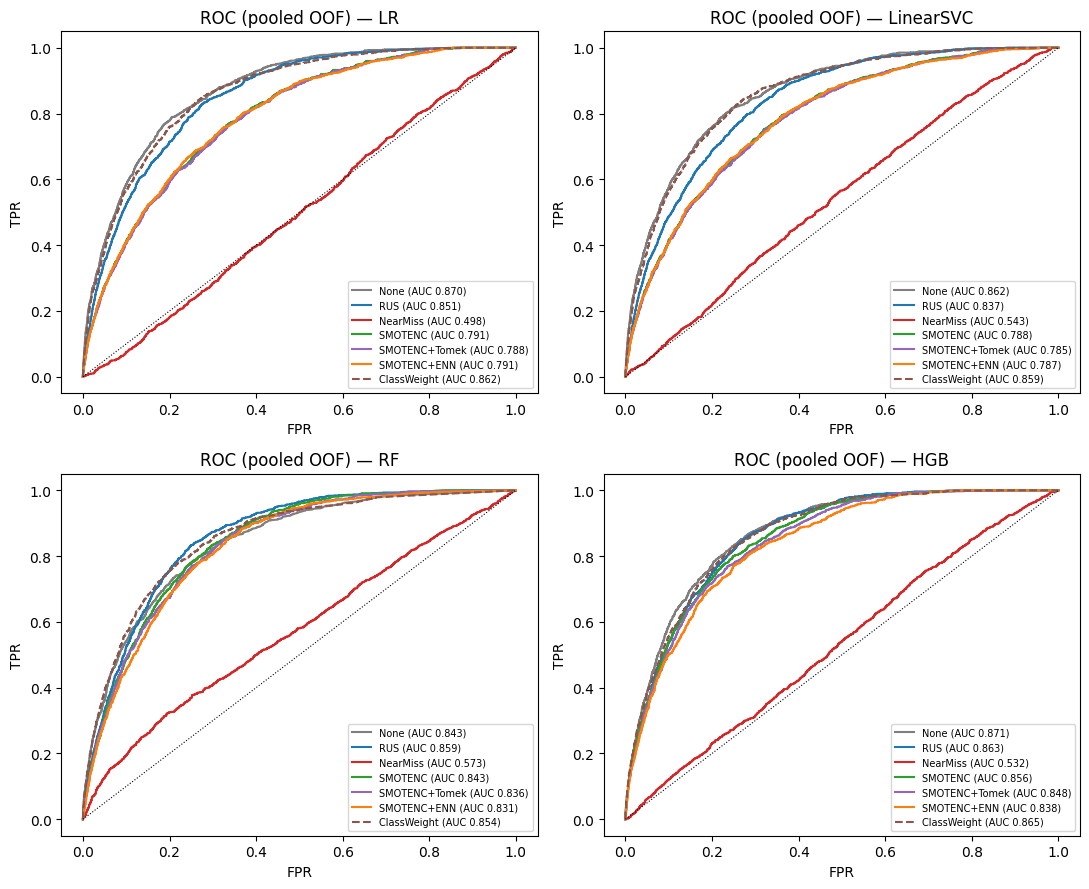

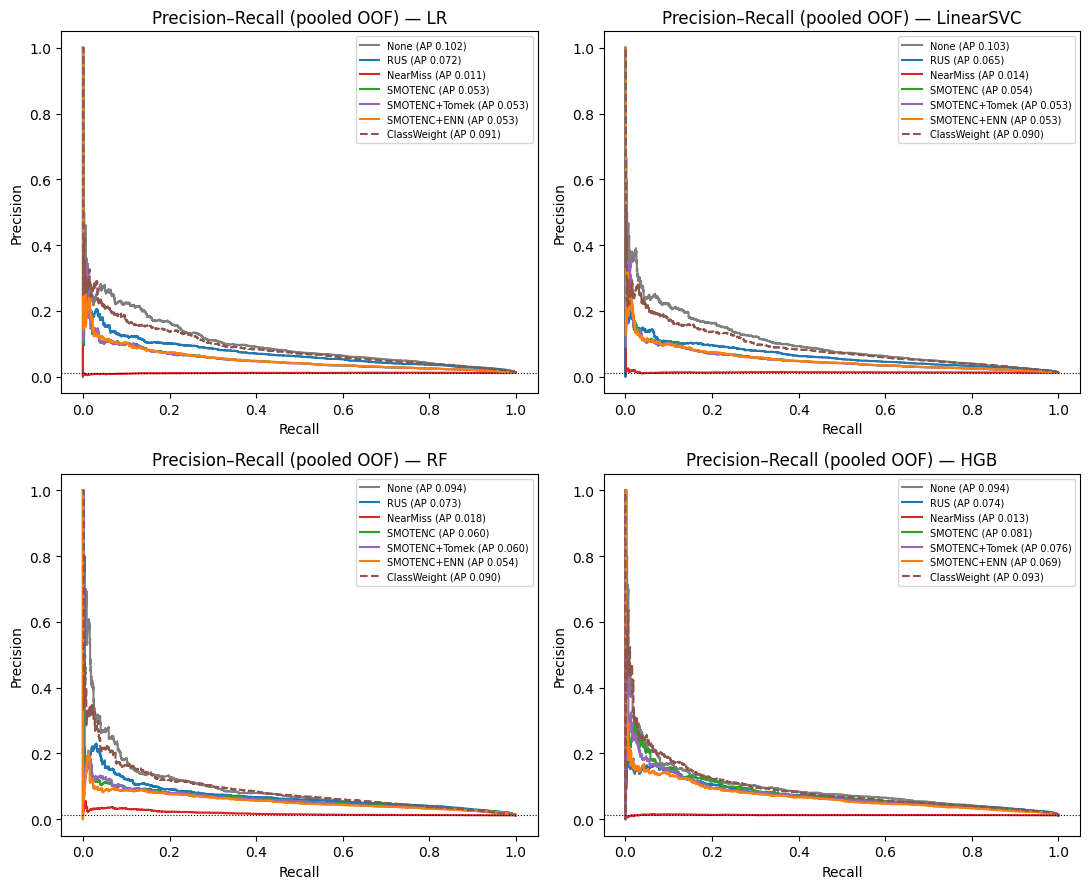

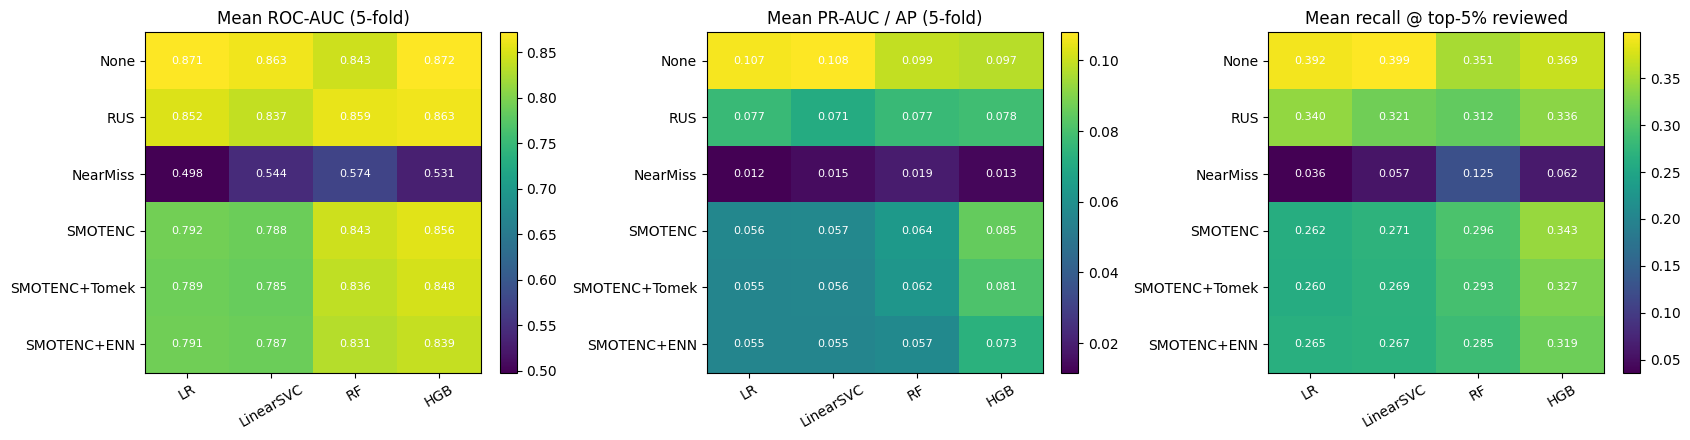

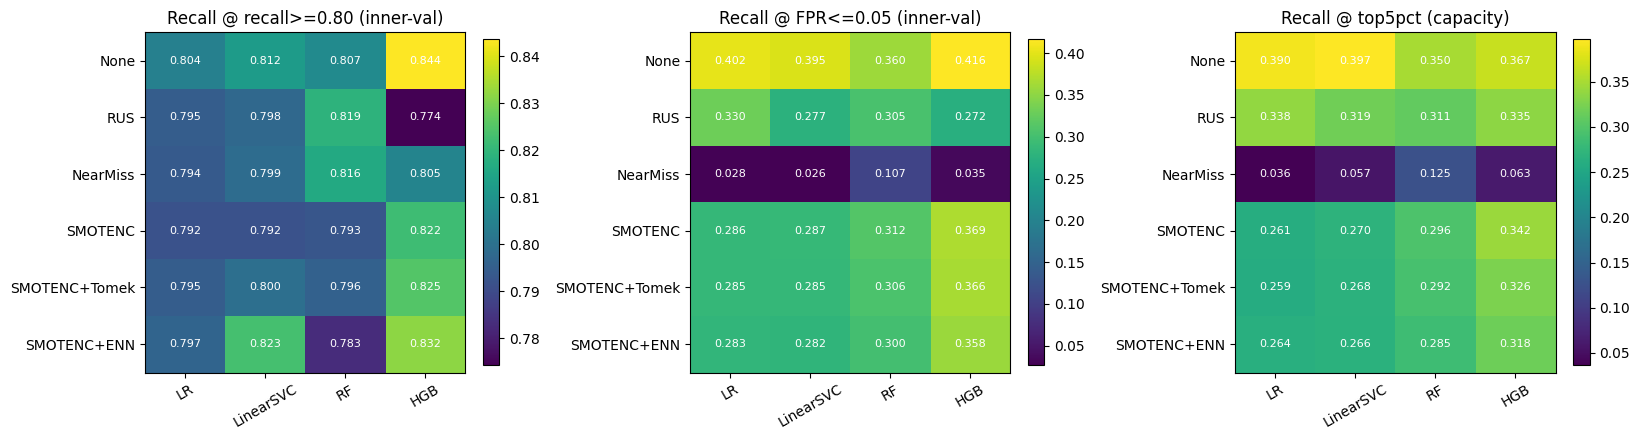

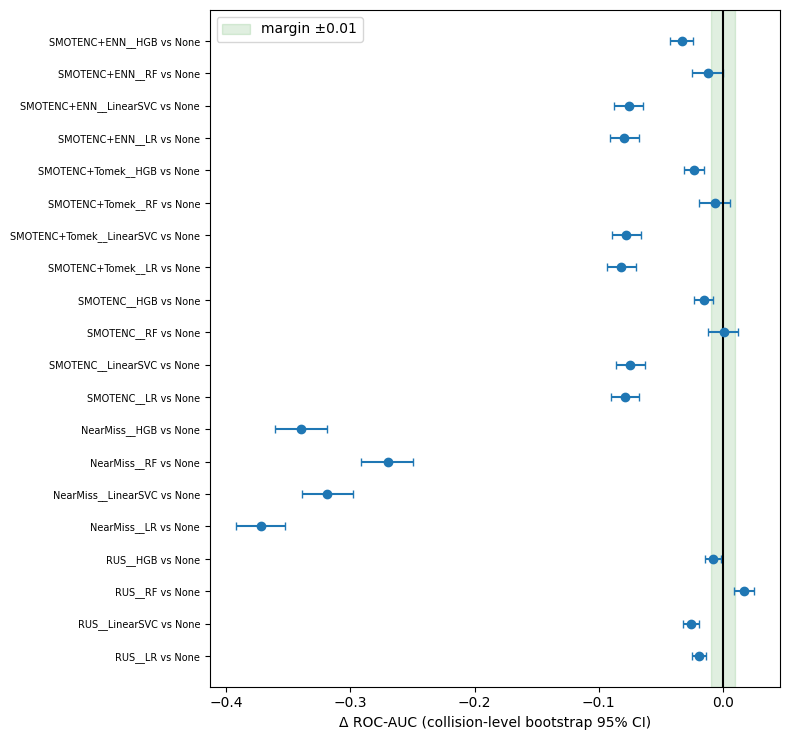

In [18]:
# %% [13] FIGUR UTAMA (dibuat dari prediksi OOF yang disimpan)
SAVED = pd.read_csv(PRED_PATH); ys = SAVED['y_true_reconciled'].values
SAMP_COL = dict(zip(SAMPLERS_MAIN + [CW], ['#7f7f7f', '#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#8c564b']))
fig, axs = plt.subplots(2, 2, figsize=(11, 9))
for ax, c in zip(axs.ravel(), CLASSIFIERS):
    for s in SAMPLERS_MAIN + ([CW] if RUN_CLASS_WEIGHT else []):
        col = f'score__{s}__{c}'
        if col in SAVED and not SAVED[col].isna().any():
            f_, t_, _ = roc_curve(ys, SAVED[col].values); ax.plot(f_, t_, color=SAMP_COL[s], label=f'{s} (AUC {roc_auc_score(ys, SAVED[col].values):.3f})', ls='--' if s == CW else '-')
    ax.plot([0, 1], [0, 1], 'k:', lw=.8); ax.set_title(f'ROC (pooled OOF) — {c}'); ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(fontsize=7)
savefig('fig04_roc_curves_oof')
fig, axs = plt.subplots(2, 2, figsize=(11, 9))
for ax, c in zip(axs.ravel(), CLASSIFIERS):
    for s in SAMPLERS_MAIN + ([CW] if RUN_CLASS_WEIGHT else []):
        col = f'score__{s}__{c}'
        if col in SAVED and not SAVED[col].isna().any():
            p_, r_, _ = precision_recall_curve(ys, SAVED[col].values); ax.plot(r_, p_, color=SAMP_COL[s], label=f'{s} (AP {average_precision_score(ys, SAVED[col].values):.3f})', ls='--' if s == CW else '-')
    ax.axhline(ys.mean(), color='k', ls=':', lw=.8); ax.set_title(f'Precision–Recall (pooled OOF) — {c}'); ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.legend(fontsize=7)
savefig('fig05_pr_curves_oof')

def heat(ax, vals, title, fmt='{:.3f}'):
    im = ax.imshow(vals.values, cmap='viridis', aspect='auto'); ax.set_xticks(range(vals.shape[1])); ax.set_xticklabels(vals.columns, rotation=30)
    ax.set_yticks(range(vals.shape[0])); ax.set_yticklabels(vals.index); ax.set_title(title)
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = vals.values[i, j]; ax.text(j, i, 'NA' if np.isnan(v) else fmt.format(v), ha='center', va='center', color='w', fontsize=8)
    plt.colorbar(im, ax=ax, fraction=.046)
H = main_sum.assign(sampler=main_sum.config.str.split('__').str[0], clf=main_sum.config.str.split('__').str[1])
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (m, t) in zip(axs, [('mean_roc_auc', 'Mean ROC-AUC (5-fold)'), ('mean_pr_auc', 'Mean PR-AUC / AP (5-fold)'), ('mean_recall_top5pct', 'Mean recall @ top-5% reviewed')]):
    heat(ax, H.pivot(index='sampler', columns='clf', values=m).reindex(SAMPLERS_MAIN)[CLASSIFIERS], t)
savefig('fig06_heatmaps_main24')
sel = [c for c in ['recall>=0.80 (inner-val)', 'FPR<=0.05 (inner-val)', 'top5pct (capacity)'] if c in cap_cmp.columns]
fig, axs = plt.subplots(1, len(sel), figsize=(5.5 * len(sel), 4.5))
axs = np.atleast_1d(axs)
for ax, op in zip(axs, sel):
    vv = OP_POOLED[(OP_POOLED.operating_point == op) & OP_POOLED.config.isin(CFG_MAIN24)]
    t_ = vv.pivot_table(index=vv.config.str.split('__').str[0], columns=vv.config.str.split('__').str[1], values='recall').reindex(SAMPLERS_MAIN)[CLASSIFIERS]
    heat(ax, t_, f'Recall @ {op}')
savefig('fig07_recall_at_operating_points')
pa = PAIRED[(PAIRED.metric == 'roc_auc') & (PAIRED.comparison.str.startswith('resampler'))].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 0.3 * len(pa) + 1.5))
ax.errorbar(pa.pooled_diff, range(len(pa)), xerr=[pa.pooled_diff - pa.ci95_low, pa.ci95_high - pa.pooled_diff], fmt='o', capsize=3)
ax.axvline(0, color='k'); ax.axvspan(-EQUIV_MARGIN, EQUIV_MARGIN, color='g', alpha=.12, label=f'margin ±{EQUIV_MARGIN}')
ax.set_yticks(range(len(pa))); ax.set_yticklabels(pa.config_A + ' vs ' + pa.config_B.str.split('__').str[0], fontsize=7); ax.set_xlabel('Δ ROC-AUC (collision-level bootstrap 95% CI)'); ax.legend()
savefig('fig08_paired_roc_auc_differences')

[S1_labelA] fold 0 outer None__LR                 resample    0.0s fit    2.5s
[S1_labelA] fold 0 outer None__HGB                resample    0.0s fit   28.6s
[S1_labelA] fold 0 outer RUS__LR                  resample    0.0s fit    0.4s
[S1_labelA] fold 0 outer RUS__HGB                 resample    0.0s fit    2.7s
[S1_labelA] fold 1 outer None__LR                 resample    0.0s fit    2.4s
[S1_labelA] fold 1 outer None__HGB                resample    0.0s fit   30.7s
[S1_labelA] fold 1 outer RUS__LR                  resample    0.0s fit    0.2s
[S1_labelA] fold 1 outer RUS__HGB                 resample    0.0s fit    2.3s
[S1_labelA] fold 2 outer None__LR                 resample    0.0s fit    2.2s
[S1_labelA] fold 2 outer None__HGB                resample    0.0s fit   30.7s
[S1_labelA] fold 2 outer RUS__LR                  resample    0.0s fit    0.1s
[S1_labelA] fold 2 outer RUS__HGB                 resample    0.0s fit    2.4s
[S1_labelA] fold 3 outer None__LR                 re

,analysis,variant,config,n_rows,n_fatal,prevalence_pct,mean_roc_auc,sd_roc_auc,mean_pr_auc,mean_recall_top5pct
0,(reference),"MAIN: label B, grouped CV, semantic, RETRO_FULL",None__HGB,85569,1023,1.195526,0.871701,0.007087,0.097468,0.368795
1,(reference),"MAIN: label B, grouped CV, semantic, RETRO_FULL",None__LR,85569,1023,1.195526,0.870773,0.007586,0.106523,0.392416
2,(reference),"MAIN: label B, grouped CV, semantic, RETRO_FULL",RUS__HGB,85569,1023,1.195526,0.863452,0.006410,0.078293,0.336416
3,(reference),"MAIN: label B, grouped CV, semantic, RETRO_FULL",RUS__LR,85569,1023,1.195526,0.851515,0.005366,0.076739,0.340432
4,(reference),"MAIN: label B, grouped CV, semantic, RETRO_FULL",NearMiss__HGB,85569,1023,1.195526,0.531424,0.018392,0.013386,0.061829
5,(reference),"MAIN: label B, grouped CV, semantic, RETRO_FULL",NearMiss__LR,85569,1023,1.195526,0.497861,0.014409,0.011654,0.036258
6,S1 label,A: enhanced==1 (pendekatan awal),None__LR,85569,565,0.660286,0.924454,0.004836,0.107371,0.522547
7,S1 label,A: enhanced==1 (pendekatan awal),None__HGB,85569,565,0.660286,0.913698,0.009803,0.080673,0.482363
8,S1 label,A: enhanced==1 (pendekatan awal),RUS__LR,85569,565,0.660286,0.904156,0.007609,0.069123,0.461216
9,S1 label,A: enhanced==1 (pendekatan awal),RUS__HGB,85569,565,0.660286,0.891481,0.012964,0.057273,0.384761



[S1 label] ROC-AUC rata-rata per varian
variant        A: enhanced==1 (pendekatan awal)  C: complete-case (−1 dikeluarkan)  MAIN: label B, grouped CV, semantic, RETRO_FULL
config                                                                                                                             
NearMiss__HGB                               NaN                                NaN                                           0.5314
NearMiss__LR                                NaN                                NaN                                           0.4979
None__HGB                                0.9137                             0.8426                                           0.8717
None__LR                                 0.9245                             0.8517                                           0.8708
RUS__HGB                                 0.8915                             0.8337                                           0.8635
RUS__LR                            

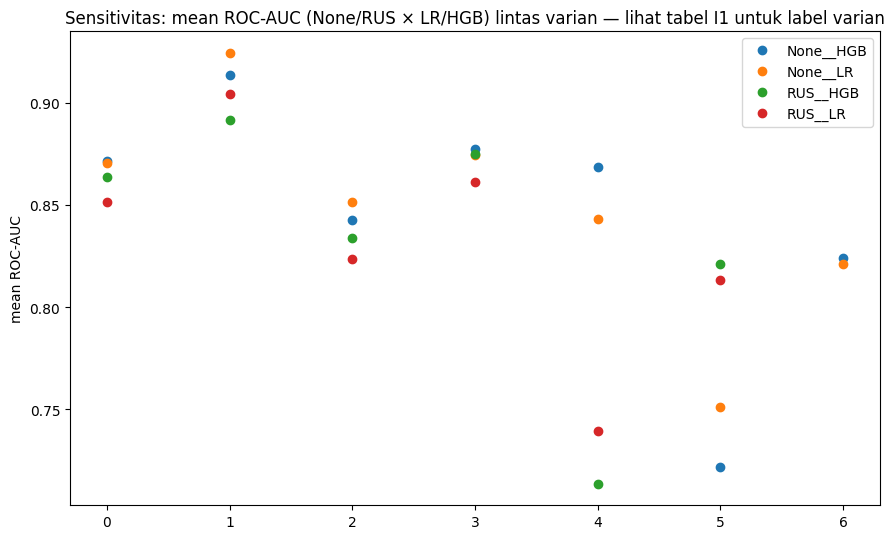

In [19]:
# %% [14] SENSITIVITAS (§3.1, §3.3, §3.4, §4.2)
SENS_ROWS = []; SENS_FITS = 0
def add_sens(analysis, variant, X, y, fold_id, oof, cfgs):
    fm = fold_metric_table(oof, y, fold_id, cfgs); sm = summarize(fm)
    for _, r in sm.iterrows():
        SENS_ROWS.append(dict(analysis=analysis, variant=variant, config=r.config, n_rows=len(y), n_fatal=int(y.sum()), prevalence_pct=100 * y.mean(),
                              mean_roc_auc=r.mean_roc_auc, sd_roc_auc=r.sd_roc_auc_across_folds, mean_pr_auc=r.mean_pr_auc, mean_recall_top5pct=r.mean_recall_top5pct))
if RUN_SENSITIVITY:
    SC = ['LR', 'HGB']; SS = ['None', 'RUS']
    ref = lambda cfgs: add_sens('(reference)', 'MAIN: label B, grouped CV, semantic, RETRO_FULL', X_SEM, Y_MAIN, FOLD_MAIN, OOF, cfgs)
    ref([f'{s}__{c}' for s in SS + ['NearMiss'] for c in SC])
    # S1 label
    r = run_cv('S1_labelA', X_SEM, y_A, GROUPS, FOLD_MAIN, SPEC_FULL, 'semantic', SS, SC, False)
    add_sens('S1 label', 'A: enhanced==1 (pendekatan awal)', X_SEM, y_A, FOLD_MAIN, r['oof'], r['configs']); SENS_FITS += len(r['times'])
    mC = y_C != -1; XC = X_SEM[mC].reset_index(drop=True); yC = y_C[mC]
    r = run_cv('S1_labelC', XC, yC, GROUPS[mC], FOLD_MAIN[mC], SPEC_FULL, 'semantic', SS, SC, False)
    add_sens('S1 label', 'C: complete-case (−1 dikeluarkan)', XC, yC, FOLD_MAIN[mC], r['oof'], r['configs']); SENS_FITS += len(r['times'])
    # S2 row-wise vs grouped
    r = run_cv('S2_rowwise', X_SEM, Y_MAIN, GROUPS, FOLD_ROW, SPEC_FULL, 'semantic', SS, SC, False)
    add_sens('S2 CV design', 'row-wise stratified CV (collision bocor)', X_SEM, Y_MAIN, FOLD_ROW, r['oof'], r['configs']); SENS_FITS += len(r['times'])
    # S3 encoding
    r = run_cv('S3_naive', X_NAIVE, Y_MAIN, GROUPS, FOLD_MAIN, SPEC_FULL, 'naive', ['None', 'NearMiss', 'SMOTE'], SC, False)
    add_sens('S3 encoding', 'naive numeric (dtype-based), SMOTE standar', X_NAIVE, Y_MAIN, FOLD_MAIN, r['oof'], r['configs']); SENS_FITS += len(r['times'])
    r = run_cv('S3_semantic_smote', X_SEM, Y_MAIN, GROUPS, FOLD_MAIN, SPEC_FULL, 'semantic', ['SMOTE'], SC, False)
    add_sens('S3 encoding', 'semantic one-hot, SMOTE standar', X_SEM, Y_MAIN, FOLD_MAIN, r['oof'], r['configs']); SENS_FITS += len(r['times'])
    # S4 prediction setting
    for nm, tiers in list(SETTINGS.items())[:2]:
        sp = make_spec(tiers)
        r = run_cv('S4_' + nm.split()[0], X_SEM, Y_MAIN, GROUPS, FOLD_MAIN, sp, 'semantic', SS, SC, False)
        add_sens('S4 prediction setting', nm, X_SEM, Y_MAIN, FOLD_MAIN, r['oof'], r['configs']); SENS_FITS += len(r['times'])
    SENS = pd.DataFrame(SENS_ROWS)
    save_table(SENS, 'I1_sensitivity_summary', 'I1. Ringkasan sensitivitas: label, desain CV, encoding, waktu prediksi (fitur)')
    for an in SENS.analysis.unique():
        if an == '(reference)': continue
        sub = SENS[SENS.analysis.isin(['(reference)', an])]
        print(f'\n[{an}] ROC-AUC rata-rata per varian'); print(sub.pivot_table(index='config', columns='variant', values='mean_roc_auc').round(4).to_string())
    fig, ax = plt.subplots(figsize=(9, 5.5)); lab = SENS[SENS.config.isin(['None__LR', 'None__HGB', 'RUS__LR', 'RUS__HGB'])]
    for (cfg), g in lab.groupby('config'): ax.plot(range(len(g)), g.mean_roc_auc.values, 'o', label=cfg)
    ax.set_title('Sensitivitas: mean ROC-AUC (None/RUS × LR/HGB) lintas varian — lihat tabel I1 untuk label varian'); ax.legend(); ax.set_ylabel('mean ROC-AUC')
    savefig('fig09_sensitivity_overview')

In [25]:
# %% [14b] SENSITIVITAS S5: HANYA 25 POLICE FORCE DENGAN CAKUPAN 100%
if RUN_SENSITIVITY:
    full_forces = cov[(cov.dimension == 'police_force') & (cov.coverage_pct == 100)].value.astype(int).tolist()
    m5 = df['police_force'].astype(int).isin(full_forces).values
    X5 = X_SEM[m5].reset_index(drop=True); y5 = Y_MAIN[m5]; g5 = GROUPS[m5]; f5 = FOLD_MAIN[m5]
    print(f'S5: {len(full_forces)} force berkoverage 100% | baris {int(m5.sum())} dari {len(m5)} | fatal {int(y5.sum())} ({100 * y5.mean():.3f}%)')
    print('Fatal per fold (outer test):', {int(k): int(y5[f5 == k].sum()) for k in np.unique(f5)})
    r = run_cv('S5_full_force', X5, y5, g5, f5, SPEC_FULL, 'semantic', SS, SC, False)
    add_sens('S5 subset cakupan 100%', f'hanya {len(full_forces)} force berkoverage 100% (label B, grouped CV, semantic)', X5, y5, f5, r['oof'], r['configs'])
    SENS_FITS += len(r['times'])
    SENS = pd.DataFrame(SENS_ROWS)
    save_table(SENS, 'I1_sensitivity_summary', 'I1. Ringkasan sensitivitas (termasuk S5)', display_it=False)
    s5 = SENS[SENS.analysis.isin(['(reference)', 'S5 subset cakupan 100%'])]
    print('\n[S5] ROC-AUC rata-rata: seluruh file (reference) vs hanya force berkoverage 100%')
    print(s5.pivot_table(index='config', columns='variant', values='mean_roc_auc').round(4).to_string())
    print('\n[S5] Recall top-5% rata-rata')
    print(s5.pivot_table(index='config', columns='variant', values='mean_recall_top5pct').round(4).to_string())
else:
    print('RUN_SENSITIVITY = False: S5 dilewati.')

S5: 25 force berkoverage 100% | baris 78047 dari 85569 | fatal 874 (1.120%)
Fatal per fold (outer test): {0: 168, 1: 174, 2: 183, 3: 185, 4: 164}
[S5_full_force] fold 0 outer None__LR                 resample    0.0s fit    4.9s
[S5_full_force] fold 0 outer None__HGB                resample    0.0s fit   30.1s
[S5_full_force] fold 0 outer RUS__LR                  resample    0.0s fit    0.8s
[S5_full_force] fold 0 outer RUS__HGB                 resample    0.0s fit    2.9s
[S5_full_force] fold 1 outer None__LR                 resample    0.0s fit    3.2s
[S5_full_force] fold 1 outer None__HGB                resample    0.0s fit   27.4s
[S5_full_force] fold 1 outer RUS__LR                  resample    0.0s fit    0.1s
[S5_full_force] fold 1 outer RUS__HGB                 resample    0.0s fit    2.9s
[S5_full_force] fold 2 outer None__LR                 resample    0.0s fit    2.3s
[S5_full_force] fold 2 outer None__HGB                resample    0.0s fit   27.4s
[S5_full_force] fold 2 o

In [26]:
# %% [15] AUDIT KLAIM, BIAYA KOMPUTASI, REPRODUCIBILITY, README, EKSPOR (§4.1, §6, §8)
T = MAIN['times']
cost = T[T.stage == 'outer'].groupby('config').agg(resample_s=('resample_s', 'mean'), fit_s=('fit_s', 'sum'), predict_s=('predict_s', 'sum'),
                                                  n_train_rows=('n_train_rows', 'mean'), n_features=('n_features', 'mean')).reset_index()
save_table(cost, 'J1_computational_cost_per_config', 'J1. Waktu komputasi (detik, wall-clock; resample_s = rata-rata per fold, fit/predict = total 5 fold)', display_it=False)
n_main_fits = int(((T.stage == 'outer') & T.config.isin(CFG_MAIN24)).sum())
fits = pd.DataFrame([
    dict(item='Main comparison: model fits (24 configs × 5 folds, outer stage)', n=n_main_fits),
    dict(item='Inner-validation refits for threshold selection (main configs)', n=int(((T.stage == 'inner') & T.config.isin(CFG_MAIN24)).sum())),
    dict(item='Supplementary class-weight fits (outer + inner)', n=int(T.config.str.startswith(CW).sum())),
    dict(item='Sensitivity-analysis fits', n=int(SENS_FITS))])
save_table(fits, 'J2_model_fit_counts', 'J2. Hitungan model fit (120 fits ≠ 120 eksperimen independen)')
save_table(MAIN['stage'], 'J3_stage_log_features_and_class_counts', 'J3. Jumlah fitur & kelas setelah setiap tahap per fold (termasuk hasil hybrid cleaning)', display_it=False)
save_table(pd.DataFrame(WARN_LOG) if WARN_LOG else pd.DataFrame(columns=['tag', 'fold', 'stage', 'config', 'category', 'message']), 'J4_warnings_log', 'J4. Log warning (termasuk konvergensi) — tidak ditekan', display_it=False)
save_table(pd.DataFrame(FAIL_LOG) if FAIL_LOG else pd.DataFrame(columns=['tag', 'fold', 'stage', 'config', 'error']), 'J5_failure_log', 'J5. Log kegagalan sampler/classifier', display_it=False)
print(f'Warnings tercatat: {len(WARN_LOG)} | Kegagalan: {len(FAIL_LOG)}')
hw = pd.DataFrame([dict(cpu_count=ENV['cpu_count'], ram_gb=ENV['ram_gb'], python=ENV['python'], **ENV['libraries'],
                        time_definition='wall-clock detik (time.perf_counter): resample = sampler fit_resample (+ encoder pada representasi hasil resample; hybrid = SMOTENC + cleaning); fit = classifier.fit; predict = skoring set evaluasi; prep bersama dicatat di J3')])
save_table(hw, 'J6_hardware_software_timing_definition', 'J6. CPU/RAM/versi & definisi waktu komputasi', display_it=False)

claim = pd.DataFrame([
    dict(claim_manuscript='Model linear selalu 0,90–0,91', status='Lihat G2: nyatakan pengecualian & rentang aktual'),
    dict(claim_manuscript='Leakage-free', status='Ganti: preprocessing/resampling hanya di training fold; split collision-grouped (D1 memverifikasi 0 collision bersama); fitur outcome-proxy dikeluarkan'),
    dict(claim_manuscript='Best model', status=f'Gunakan "combination with the highest mean cross-validated ROC-AUC" = {BEST_AUC}'),
    dict(claim_manuscript='SD antarmetode = stabilitas', status='Gunakan "between-method dispersion" (G1); variasi antar-split di E2'),
    dict(claim_manuscript='Missing values hanya delapan kolom', status='Pisahkan native NaN vs coded −1 (C1)'),
    dict(claim_manuscript='Min–max selalu [0,1]', status='Hanya pada data training; lihat J3 (share sel uji di luar rentang training)'),
    dict(claim_manuscript='Dense conversion sangat mempercepat', status='Tidak diuji; nyatakan sebagai pilihan implementasi (matriks dense dipakai)'),
    dict(claim_manuscript='Mekanisme intercept / tied RF scores', status='Hipotesis interpretatif; G3 hanya diagnostik skor bertabrakan'),
    dict(claim_manuscript='NearMiss should be avoided', status='Batasi pada data, encoding, dan konfigurasi studi; lihat S3 (I1)'),
    dict(claim_manuscript='UK versus Great Britain', status='Gunakan Great Britain secara konsisten'),
])
save_table(claim, 'K1_claim_audit_checklist', 'K1. Checklist audit konsistensi klaim (§6)', display_it=False)

top = main_sum.iloc[0]
readme = f"""RINGKASAN OTOMATIS — pipeline revisi STATS19 (dibuat {ENV['timestamp']})
Input: {PROV['input_file']} | sha256 {PROV['sha256'][:16]}… | baris {N_FILE_ROWS:,} | collision {N_FILE_COLL:,}
Label: reconciled (B): fatal = {int(Y_MAIN.sum())} ({100 * Y_MAIN.mean():.3f}%); pendekatan awal (A): {n_enh_fatal} fatal; kode -1 pada enhanced severity = {n_m1:,} baris,
  di antaranya {n_m1_fatal} fatal menurut casualty_severity standar (sebelumnya dilabel non-fatal).
Validasi: StratifiedGroupKFold {N_SPLITS}-fold, group = accident_index (collision); collision bersama train/test = 0 (D1).
Inner validation ({INNER_SPLITS}-fold grouped) dipakai untuk memilih threshold; threshold tidak dioptimalkan di test fold.
Kalimat saran: "Twenty-four sampling–classifier configurations were evaluated using five-fold collision-grouped cross-validation,
  resulting in {n_main_fits} model fits in the main comparison." (refit inner/suplemen/sensitivitas dilaporkan terpisah, J2).
Konfigurasi dengan mean ROC-AUC tertinggi: {BEST_AUC} ({top.mean_roc_auc:.4f}); ini BUKAN otomatis "best model" untuk deteksi (lihat E3, F4).
Setting prediksi utama: retrospective classification dari catatan polisi lengkap (RETRO_FULL); jangan klaim triase real-time. Sensitivitas: S4.
Representasi: fitur dikelompokkan menurut makna (C2); SMOTENC + one-hot setelah resampling; SMOTE standar/encoding naif hanya sebagai sensitivitas (S3).
Metrik: ROC-AUC = area under ROC; PR-AUC = average precision (tanpa interpolasi linear); margin kesetaraan praktis ±{EQUIV_MARGIN} (keputusan peneliti).
Catatan: tier ketersediaan fitur (C3) dan margin kesetaraan adalah asumsi yang perlu divalidasi peneliti; angka rujukan nasional dikutip dari manuskrip.
Isi folder: tables/*.csv, figures/*.png, predictions/oof_predictions_main.csv.gz, environment.json, requirements_used.txt, supplementary_tables.xlsx
"""
open(os.path.join(OUT_DIR, 'README_hasil.txt'), 'w').write(readme); print(readme)

xl = os.path.join(OUT_DIR, 'supplementary_tables.xlsx')
with pd.ExcelWriter(xl, engine='openpyxl') as w:
    for nm, t in TABLES.items():
        if len(t) <= 100000: t.to_excel(w, sheet_name=nm[:31], index=False)
zpath = os.path.join(OUT_DIR, 'hasil_stats19.zip')
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(OUT_DIR):
        if CKPT_DIR in root or root == OUT_DIR and False: continue
        for f in fs:
            if f.endswith('.zip'): continue
            p = os.path.join(root, f); z.write(p, os.path.relpath(p, OUT_DIR))
print('Semua hasil:', OUT_DIR, '\nZIP:', zpath)
if IN_COLAB:
    try:
        from google.colab import files; files.download(zpath)
    except Exception as e: print('Unduh manual dari panel Files:', zpath)


J2. Hitungan model fit (120 fits ≠ 120 eksperimen independen)


,item,n
0,"Main comparison: model fits (24 configs × 5 folds, outer stage)",120
1,Inner-validation refits for threshold selection (main configs),120
2,Supplementary class-weight fits (outer + inner),40
3,Sensitivity-analysis fits,160


Warnings tercatat: 150 | Kegagalan: 0
RINGKASAN OTOMATIS — pipeline revisi STATS19 (dibuat 2026-11-17T02:32:43)
Input: Dataset_Final_.csv | sha256 d5ef05fcbb5cab10… | baris 85,569 | collision 67,879
Label: reconciled (B): fatal = 1023 (1.196%); pendekatan awal (A): 565 fatal; kode -1 pada enhanced severity = 46,616 baris,
  di antaranya 458 fatal menurut casualty_severity standar (sebelumnya dilabel non-fatal).
Validasi: StratifiedGroupKFold 5-fold, group = accident_index (collision); collision bersama train/test = 0 (D1).
Inner validation (4-fold grouped) dipakai untuk memilih threshold; threshold tidak dioptimalkan di test fold.
Kalimat saran: "Twenty-four sampling–classifier configurations were evaluated using five-fold collision-grouped cross-validation,
  resulting in 120 model fits in the main comparison." (refit inner/suplemen/sensitivitas dilaporkan terpisah, J2).
Konfigurasi dengan mean ROC-AUC tertinggi: None__HGB (0.8717); ini BUKAN otomatis "best model" untuk deteksi (lihat

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>